In [1]:
import re                              # Regular expressions: split news text into tokens
from collections import Counter         # Count how frequently each token appears

import pandas as pd                     # Store experiment results as tables
from datasets import load_dataset       # Download AG News from Hugging Face
import matplotlib.pyplot as plt         # Draw learning curves

import torch                            # PyTorch core: tensors and automatic gradients
import torch.nn as nn                   # Neural network layers and loss functions
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
# pack_padded_sequence: let LSTM ignore padding; pad_sequence: make equal-length batches
from torch.utils.data import DataLoader, Dataset, random_split
# Dataset represents individual articles; DataLoader groups them into batches


c:\Users\William\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Text Processing — Tokenize text and build vocabulary [Person 6: No need to run]

In [2]:
# Reserve two special integer IDs: padding (0) and unknown word (1).
PAD, UNK = "<pad>", "<unk>"
PAD_IDX, UNK_IDX = 0, 1


def tokenize(text: str):
    """Turn a news article into lowercase word and punctuation tokens."""
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?|[^\sa-z0-9]", text.lower())


def build_vocab(texts, min_freq=5, max_size=30_000):
    """Create a mapping between frequently used words and their integer IDs."""
    counter = Counter()
    for t in texts:
        counter.update(tokenize(t))  # Count word frequency across the input articles.

    itos = [PAD, UNK]  # Index-to-string list; index 0 is PAD, 1 is UNK.
    for word, freq in counter.most_common(max_size):
        if freq < min_freq:  # Skip words that are too rare.
            break
        itos.append(word)

    stoi = {w: i for i, w in enumerate(itos)}  # String-to-index dictionary.
    return stoi, itos


def encode(text, stoi, max_len):
    """Convert text to token IDs and truncate to max_len tokens."""
    ids = [stoi.get(tok, UNK_IDX) for tok in tokenize(text)][:max_len]
    return ids if ids else [UNK_IDX]  # Avoid empty sequences, which LSTM cannot pack.

# Tiny example only. These mappings will be rebuilt using all AG News train text later.
example = "Wall St. Bears Claw Back Into the Black (Reuters)"
print(tokenize(example))
stoi, itos = build_vocab([example], min_freq=1)
print(stoi)
print(encode(example, stoi, max_len=10))


['wall', 'st', '.', 'bears', 'claw', 'back', 'into', 'the', 'black', '(', 'reuters', ')']
{'<pad>': 0, '<unk>': 1, 'wall': 2, 'st': 3, '.': 4, 'bears': 5, 'claw': 6, 'back': 7, 'into': 8, 'the': 9, 'black': 10, '(': 11, 'reuters': 12, ')': 13}
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


# AG News Dataset — Data source and class definitions [Person 6: No need to run]

AG is a collection of more than 1 million news articles. The AG's news topic classification dataset is constructed by choosing 4 largest classes from the original corpus. Each class contains 30,000 training samples and 1,900 testing samples. The total number of training samples is 120,000 and testing 7,600.

See details here: https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset?select=test.csv

Class Index:
1-World, 2-Sports, 3-Business, 4-Sci/Tech

In [3]:
# Class IDs are 0 to 3. The Linear layer must return one logit for each class.
CLASSES = ["World", "Sports", "Business", "Sci/Tech"]


In [4]:
# Load original AG News splits: train (120,000) and test (7,600).
raw = load_dataset("aRWA787/ag_news_dataset")
print(raw["train"][0])

# Build the token-ID dictionary once, so the same vocabulary is used for all data.
# Note: this uses the full original train split, before train/validation splitting.
stoi, itos = build_vocab(raw["train"]["text"])
print("Vocab size:", len(itos))  # Number of IDs available to the Embedding layer.


{'text': "wall st. bears claw back into the black (reuters) reuters - short-sellers, wall street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2, 'label_name': 'Business', 'length': 144}
Vocab size: 28384


## Prepare Training, Validation, and Test Data [Person 6: No need to run]

Build the training and test sets by encoding the text.

- Only read MAX_LEN tokens from each article.
    - The longer the sequence, the harder it is for the a vanilla RNN to learn from early tokens due to vanishing gradients. So, shorter MAX_LEN trains better (and faster).
    - AG News articles are a headline + short description, so most of the topic signal is in the first 30 or so tokens.

In [5]:
MAX_LEN = 48        # Maximum tokens per article after truncation, NOT number of articles.
BATCH_SIZE = 128    # Maximum articles in one mini-batch (one optimizer update).
SEED = 8567         # Random seed for repeatable train/validation split.

class NewsDataset(Dataset):
    def __init__(self, hf_split, stoi, max_len):
        self.labels = list(hf_split["label"])  # One class ID (0..3) per article.
        self.data = [encode(t, stoi, max_len) for t in hf_split["text"]]
        # self.data contains variable-length token-ID lists, each with <= MAX_LEN elements.

    def __len__(self):
        return len(self.labels)  # Total number of articles.

    def __getitem__(self, i):
        return self.data[i], self.labels[i]  # Return (token IDs, true class ID).


def collate(batch):
    """Pad articles in one batch and return their true sequence lengths."""
    seqs, labels = zip(*batch)  # Lists of token IDs and labels from B articles.
    lengths = torch.tensor([len(s) for s in seqs], dtype=torch.long)  # (B,)
    padded = pad_sequence(
        [torch.tensor(s, dtype=torch.long) for s in seqs],
        batch_first=True,          # Output shape: (B, T) rather than (T, B).
        padding_value=PAD_IDX,    # Shorter articles get 0s on the RIGHT.
    )
    # B = number of articles (usually 128); T = longest length in THIS batch (<= 48).
    return padded, lengths, torch.tensor(labels, dtype=torch.long)
    # Shapes: tokens (B, T), lengths (B,), labels (B,).

# Prepare integer sequences once. No extra preprocessing needed in Part 5.
full_train = NewsDataset(raw["train"], stoi, MAX_LEN)
test_ds = NewsDataset(raw["test"], stoi, MAX_LEN)

# Reserve 10% of the original 120,000 training rows for validation.
n_val = int(0.1 * len(full_train))
train_ds, val_ds = random_split(
    full_train,
    [len(full_train) - n_val, n_val],
    generator=torch.Generator().manual_seed(SEED),  # Fixed split indices.
)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
# Shuffle training articles to change the minibatch order.
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, collate_fn=collate)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, collate_fn=collate)
# No shuffling is required for validation/test metrics.

print("Train:", len(train_ds), "Val:", len(val_ds), "Test:", len(test_ds))


Train: 108000 Val: 12000 Test: 7600


# Person 5 — PyTorch **Bidirectional LSTM** and Four-Hyperparameter Tuning

**New architecture (this notebook):** `Token IDs → Embedding → Input Dropout → 1-layer Bidirectional LSTM → Output Dropout → Linear (4 logits)`.

The **original Ver4 dataset preparation and three tuning ranges remain unchanged**; the Dropout sweep is now **five evenly spaced rates from 0.0 to 0.5**, with a shared Dropout baseline of **0.25**. The architecture is now one bidirectional LSTM layer (forward and backward directions) instead of one unidirectional LSTM layer. Two independent `nn.Dropout` modules use the **same candidate rate** `p`: one on embeddings before the LSTM and another on the final concatenated representation. This keeps dropout as **one of four** tuned hyperparameters; sharing the rate is a deliberate simplification, not an LSTM requirement.

**How to obtain results for the NEW architecture (Person 5):**

1. **Run all cells** from Step 1 through Step 9, including the shared baseline (Step 4B), all four Step 5 sweeps, optional Step 7 combinations, and full-data Step 8 training. Then run Steps 11–13.
2. Step 12 evaluates per-class recall and the five shared illustrative headlines; Step 13 **automatically exports** a Person 6 package (`.zip`, `.md`, `.json`, `.csv`, `.png`, and a model checkpoint).
3. **Save the notebook after executing it** (`File → Save`). Person 6 can read the saved tables and plots without running training and can use the ZIP without a Python environment.

**Important:** Previous unidirectional-LSTM results in the source file do **not** apply to this new architecture. All old execution counts and outputs have intentionally been cleared. This notebook does **not** claim any new test accuracy until you run the experiments.

**Experimental design:** One-Factor-at-a-Time (OFAT); three sweep ranges unchanged and the Dropout range revised to `[0.0, 0.125, 0.25, 0.375, 0.5]`, 17 distinct baseline/single-parameter configurations, plus three optional combination tests. Same original data split, tokenization, and maximum sequence length of 48 tokens. The held-out test split is used only after model selection.


## Step 1 — Check Input Tensors [Run once for setup; Person 6: No need to run]


**Four important symbols:** `B = Batch Size` (number of news articles processed together), `T = Sequence Length` (longest token sequence in the current batch), `E = Embedding Dimension` (number of features per token), and `H = Hidden Size` (number of features in the LSTM hidden state).

- `tokens` has shape **`(B, T)`**. For example, `(128, 48)` means 128 news articles, each represented by up to 48 integer token IDs. Because we use **dynamic padding**, the actual value of `T` can be smaller than 48.
- `lengths` has shape **`(B,)`**. Each entry gives the number of real tokens in an article, excluding padding.
- `labels` has shape **`(B,)`**. Each entry is the correct class ID: `0`, `1`, `2`, or `3`.
- `vocab_size` is approximately 28,000. It is **not** one of the dimensions in `(128, 48)`; it is the number of distinct token IDs that the Embedding layer can look up.

> **Why check tensor shapes?** Every neural network layer expects a specific input format. `nn.Embedding` takes integer token IDs, while `nn.LSTM` processes floating-point word vectors. This checkpoint inspects the data; it does not train the model.

In [6]:
import copy       # Save a separate copy of the best model weights.
import random     # Control Python random seed.
import time       # Measure training duration in seconds.

import numpy as np
from sklearn.metrics import f1_score

# GPU (CUDA) speeds up many tensor operations; CPU works too.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VOCAB_SIZE = len(itos)  # Number of distinct token IDs, including PAD and UNK.
N_CLASSES = len(CLASSES)  # 4 categories: World, Sports, Business, Sci/Tech.

# Set seeds so repeated runs are more comparable (hardware may still differ).
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# next(iter(...)) retrieves ONE batch without starting model training.
x_batch, lengths_batch, y_batch = next(iter(train_dl))
print("Device:", device)
print("Vocabulary size:", VOCAB_SIZE)
print("Tokens:", tuple(x_batch.shape), "Lengths:", tuple(lengths_batch.shape),
      "Labels:", tuple(y_batch.shape))
print("Labels range:", int(y_batch.min()), "to", int(y_batch.max()))
# Expected: tokens (B, T), lengths (B,), labels (B,), B usually 128, T <= 48.


Device: cpu
Vocabulary size: 28384
Tokens: (128, 48) Lengths: (128,) Labels: (128,)
Labels range: 0 to 3


## Step 2 — Define a **Single-Layer Bidirectional LSTM** with Two Dropout Positions

| Operation | Input | Output | Meaning |
|---|---|---|---|
| `nn.Embedding` | `(B, T)` | `(B, T, E)` | Trainable vector for each token ID |
| **Input `nn.Dropout(p)`** | `(B, T, E)` | `(B, T, E)` | Randomly mask embedding features during **training only** |
| `pack_padded_sequence` | `(B, T, E)` | `PackedSequence` | Remove padded time steps from recurrent computation |
| **Bidirectional `nn.LSTM`** | Packed sequence | `hidden: (2, B, H)` | One layer, two directions, each with its own recurrent weights |
| Concatenate `hidden[-2]` and `hidden[-1]` | Two `(B, H)` tensors | `(B, 2H)` | Forward final state + backward final state |
| **Output `nn.Dropout(p)`** | `(B, 2H)` | `(B, 2H)` | Regularize the article representation before classification |
| `nn.Linear` | `(B, 2H)` | `(B, 4)` | Four raw class logits; no Softmax before CrossEntropyLoss |

**Example baseline dimensions:** with `B=128`, `T≤48`, `E=64`, `H=64`: `(128,T)` → `(128,T,64)` → packed BiLSTM → `(128,128)` → `(128,4)`.

**Why `hidden[-2]` and `hidden[-1]`?** For one bidirectional layer, `hidden` contains the final *forward* and final *backward* states in that order. Concatenate both; selecting only `hidden[-1]` would discard the forward direction. Packed sequences ensure that the reverse direction processes real tokens without interpreting right padding as text.

**Dropout details:** Two distinct `nn.Dropout` instances produce separate random masks; both are governed by the same tuned hyperparameter `p`. These are **not** PyTorch's built-in inter-layer LSTM dropout (which has no effect for a one-layer LSTM). Validation and inference use `model.eval()`, which turns both dropout modules off.


In [7]:
class LSTMClassifier(nn.Module):
    """Single-layer bidirectional LSTM, with input and output dropout.

    The four tuned parameters stay: embedding_dim, hidden_dim, dropout, learning_rate.
    Both dropout positions use the same p but independent random masks.
    """
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=64, dropout=0.25):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)

        # Input dropout regularizes the token embedding features BEFORE LSTM.
        self.input_dropout = nn.Dropout(dropout)

        # One recurrent layer in TWO directions; internal dropout=0 (not used).
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True,
        )

        # Output dropout regularizes the concatenated representation AFTER LSTM.
        self.output_dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden_dim, N_CLASSES)  # (B,2H) -> (B,4)

    def forward(self, tokens, lengths):
        # Integer token IDs -> float embeddings: (B,T) -> (B,T,E).
        embedded = self.embedding(tokens)
        embedded = self.input_dropout(embedded)  # same shape, dropout when training

        # Exclude padding from both forward and backward recurrent computations.
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, cell) = self.lstm(packed)
        # One layer * two directions => hidden shape (2,B,H).
        # hidden[-2] = last FORWARD state; hidden[-1] = last BACKWARD state.
        final_hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)  # (B,2H)

        final_hidden = self.output_dropout(final_hidden)
        logits = self.fc(final_hidden)  # (B,4), raw class scores
        return logits

# A forward-pass shape check. This builds randomly initialized weights only.
example_model = LSTMClassifier(VOCAB_SIZE).to(device)
example_model.eval()  # Disable both dropout modules for inspection.
with torch.no_grad():
    sample_logits = example_model(x_batch.to(device), lengths_batch)
print("Model:", "1-layer Bidirectional LSTM + Input Dropout + Output Dropout")
print("Hidden directions:", example_model.lstm.num_directions if hasattr(example_model.lstm, "num_directions") else 2)
print("Model output (logits) shape:", tuple(sample_logits.shape))
print("Baseline trainable parameters:", sum(p.numel() for p in example_model.parameters()))
assert sample_logits.shape == (x_batch.shape[0], N_CLASSES)


Model: 1-layer Bidirectional LSTM + Input Dropout + Output Dropout
Hidden directions: 2
Model output (logits) shape: (128, 4)
Baseline trainable parameters: 1883652


### Step 2A — Check Bidirectional Tensor Shapes [Optional]

The model now outputs a **2H-dimensional article representation** because it concatenates one forward and one backward final hidden state. For the baseline `E=64`, `H=64`, `B=128`, the representation is `(128,128)`, followed by four logits `(128,4)`.

`num_layers=1` still means **one recurrent layer**. Bidirectionality doubles the directions, not the number of stacked LSTM layers. The input/output dropout operations do not change tensor shapes.


In [8]:
# Shape inspection, no training.
B, T = x_batch.shape
example_model.eval()
with torch.no_grad():
    token_ids = x_batch.to(device)
    word_vectors = example_model.embedding(token_ids)
    packed = pack_padded_sequence(
        word_vectors, lengths_batch.cpu(), batch_first=True, enforce_sorted=False
    )
    _, (direction_states, _) = example_model.lstm(packed)
    article_features = torch.cat((direction_states[-2], direction_states[-1]), dim=1)
    output_scores = example_model(token_ids, lengths_batch)
    predicted_class = output_scores.argmax(dim=1)

print(f"Token IDs: {tuple(x_batch.shape)} (B={B}, T={T})")
print("Embeddings:", tuple(word_vectors.shape), "= (B,T,E)")
print("Final directional states:", tuple(direction_states.shape), "= (2,B,H)")
print("Concatenated article features:", tuple(article_features.shape), "= (B,2H)")
print("Class logits:", tuple(output_scores.shape), "= (B,4)")
print("Predicted labels:", tuple(predicted_class.shape), "= (B,)")
assert article_features.shape == (B, 2 * example_model.lstm.hidden_size)
print("First predicted class:", CLASSES[predicted_class[0].item()])


Token IDs: (128, 48) (B=128, T=48)
Embeddings: (128, 48, 64) = (B,T,E)
Final directional states: (2, 128, 64) = (2,B,H)
Concatenated article features: (128, 128) = (B,2H)
Class logits: (128, 4) = (B,4)
Predicted labels: (128,) = (B,)
First predicted class: Business


## Step 3 — Training and Validation Functions [Run once for setup; Person 6: No need to run]


**Training loop for each mini-batch:**

1. `model(tokens, lengths)`: Perform **forward propagation** and produce logits with shape `(B, 4)`.
2. `loss = CrossEntropyLoss(logits, labels)`: Compare the logits against the true class IDs with shape `(B,)` and calculate a **scalar loss** (shape `()`).
3. `optimizer.zero_grad()`: Clear gradients from the previous batch. Otherwise, PyTorch would **accumulate** gradients by default.
4. `loss.backward()`: Use **autograd / backpropagation** to calculate gradients for every trainable parameter.
5. `optimizer.step()`: Let the Adam optimizer update model weights using those gradients and the learning rate.

**Validation** uses `model.eval()` and disables gradient tracking. It calculates metrics but **does not update** weights. `argmax(dim=1)` converts logits of shape `(B, 4)` into predicted class IDs of shape `(B,)`.

In general, a lower **loss** indicates a better fit to the true categories; **accuracy** is the fraction of correctly classified articles; **macro-F1** averages the per-class F1 scores. `training_time_s` measures training steps only, while `total_fit_time_s` includes both training and validation.

In [9]:
def run_epoch(model, loader, criterion, optimizer=None):
    # optimizer=None means evaluation/validation; otherwise train the model.
    is_training = optimizer is not None
    model.train() if is_training else model.eval()
    # train() turns Dropout ON; eval() turns Dropout OFF.

    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    all_labels, all_preds = [], []  # Needed for macro-F1 and confusion matrix.

    with torch.set_grad_enabled(is_training):  # No gradient graph during evaluation.
        for tokens, lengths, labels in loader:  # One batch at a time.
            tokens = tokens.to(device)  # (B,T), send input IDs to CPU/GPU.
            labels = labels.to(device)  # (B,), true category IDs.
            logits = model(tokens, lengths)  # Forward: (B,T) -> (B,4).
            loss = criterion(logits, labels)  # One scalar cross-entropy loss.

            if is_training:
                optimizer.zero_grad()  # Reset old gradients (PyTorch accumulates by default).
                loss.backward()        # Backpropagation: compute dLoss/dWeights.
                optimizer.step()       # Adam: update weights using gradients.

            predictions = logits.argmax(dim=1)  # (B,4) -> (B,), predicted class IDs.
            n = labels.size(0)                  # Actual batch size (last batch may be smaller).
            total_loss += loss.item() * n       # Weight mean batch loss by batch size.
            total_correct += (predictions == labels).sum().item()
            total_samples += n
            all_labels.extend(labels.cpu().tolist())
            all_preds.extend(predictions.cpu().tolist())

    return {
        "loss": total_loss / total_samples,          # Mean loss per article.
        "accuracy": total_correct / total_samples,  # Proportion correct, from 0 to 1.
        "macro_f1": f1_score(all_labels, all_preds, labels=list(range(N_CLASSES)),
                             average="macro", zero_division=0),
        "labels": all_labels,
        "predictions": all_preds,
    }


def sync_gpu():
    # CUDA operations can be asynchronous; synchronize before timing on GPU.
    if device.type == "cuda":
        torch.cuda.synchronize()


def make_train_loader(dataset):
    # shuffle=True changes training batch order; fixed seed aids comparisons.
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                      collate_fn=collate, generator=torch.Generator().manual_seed(SEED))


def make_eval_loader(dataset):
    # No shuffle needed for validation/test; do not update their labels.
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)


def train_model(config, train_dataset, val_dataset, epochs=3, verbose=True):
    # Set same random seed at the start of each tuning run.
    torch.manual_seed(SEED)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(SEED)

    # config is a dictionary: embedding_dim, hidden_dim, dropout, learning_rate.
    model = LSTMClassifier(
        VOCAB_SIZE, config["embedding_dim"], config["hidden_dim"], config["dropout"]
    ).to(device)
    criterion = nn.CrossEntropyLoss()  # Multiclass classification objective.
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    train_loader = make_train_loader(train_dataset)
    validation_loader = make_eval_loader(val_dataset)

    history = []                 # Store learning curve points for every epoch.
    best_val_acc = -1.0          # Every valid accuracy >= 0 beats this.
    best_val_loss = float("inf") # Tie-breaker if two validation accuracies match.
    best_state = None            # Best checkpoint (a COPY of model weights).
    best_epoch = None
    training_time_s = 0.0
    sync_gpu()
    full_start = time.perf_counter()  # Total time includes train + validation.

    for epoch in range(1, epochs + 1):
        sync_gpu()
        epoch_start = time.perf_counter()
        train_metrics = run_epoch(model, train_loader, criterion, optimizer)
        sync_gpu()
        epoch_train_s = time.perf_counter() - epoch_start
        training_time_s += epoch_train_s

        # Validation is always performed without an optimizer (no updates).
        val_metrics = run_epoch(model, validation_loader, criterion)
        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "accuracy_gap": train_metrics["accuracy"] - val_metrics["accuracy"],
            "epoch_train_time_s": epoch_train_s,
        }
        history.append(row)

        # Select only by VALIDATION data; never choose weights using Test Accuracy.
        improved = (row["val_accuracy"] > best_val_acc or
                    (row["val_accuracy"] == best_val_acc and row["val_loss"] < best_val_loss))
        if improved:
            best_val_acc = row["val_accuracy"]
            best_val_loss = row["val_loss"]
            best_state = copy.deepcopy(model.state_dict())  # Save independent best weights.
            best_epoch = epoch

        if verbose:
            print(f"Epoch {epoch}/{epochs} | "
                  f"train acc {row['train_accuracy']:.3f}, "
                  f"val acc {row['val_accuracy']:.3f}, "
                  f"train loss {row['train_loss']:.3f}, "
                  f"val loss {row['val_loss']:.3f}")

    sync_gpu()
    total_fit_time_s = time.perf_counter() - full_start
    model.load_state_dict(best_state)  # Restore validation-best weights for later use.
    history_df = pd.DataFrame(history)
    best_row = history_df.loc[history_df["epoch"] == best_epoch].iloc[0].to_dict()

    return model, history_df, best_row, {
        "best_epoch": best_epoch,
        "training_time_s": training_time_s,
        "total_fit_time_s": total_fit_time_s,
        "parameters": sum(p.numel() for p in model.parameters()),  # Model parameter count.
    }


## Step 4 — Shared Tuning Setup [Run once]

**Purpose:** Define the updated Ver4 four-parameter tuning design for the **new fixed BiLSTM architecture**.

- Same train subset: **20,000** articles; validation subset: **4,000**.
- Same budget: **5 epochs per candidate**.
- Same baseline: `Embedding=64, Hidden=64, Dropout=0.25, Learning Rate=0.001`.
- Fixed architecture: **one-layer, bidirectional**, with **input and output dropout sharing the rate p**.
- Embedding Dimension, Hidden Size, and Learning Rate keep their original candidate values. The Dropout sweep changes to five evenly spaced values in `[0.0, 0.5]`, including the new baseline `0.25`.

Rerunning this setup clears the in-memory sweep result variables. Do not confuse earlier saved results from the former unidirectional model with new results.


In [10]:
from torch.utils.data import Subset

# Shared settings for every sweep
TUNE_TRAIN_SIZE = min(20_000, len(train_ds))
TUNE_VAL_SIZE = min(4_000, len(val_ds))
TUNE_EPOCHS = 5

# Select fixed subsets once. All parameter values use the SAME articles.
train_indices = torch.randperm(
    len(train_ds), generator=torch.Generator().manual_seed(SEED + 1)
)[:TUNE_TRAIN_SIZE].tolist()
val_indices = torch.randperm(
    len(val_ds), generator=torch.Generator().manual_seed(SEED + 2)
)[:TUNE_VAL_SIZE].tolist()
tune_train_ds = Subset(train_ds, train_indices)
tune_val_ds = Subset(val_ds, val_indices)

BASELINE = {
    "embedding_dim": 64,
    "hidden_dim": 64,
    "dropout": 0.25,
    "learning_rate": 0.001,
}

PARAMETER_LABELS = {
    "embedding_dim": "Embedding Dimension",
    "hidden_dim": "LSTM Hidden Size",
    "dropout": "Dropout Rate",
    "learning_rate": "Learning Rate",
}

# Store results from each independent tuning section.
sweep_results = {}
sweep_histories = {}

print(f"Tuning subset: {len(tune_train_ds)} train / {len(tune_val_ds)} validation")
print("Epochs per model:", TUNE_EPOCHS)

# Optional downstream results start empty until their steps are run.
combination_results = None
final_model = None


Tuning subset: 20000 train / 4000 validation
Epochs per model: 5


### Step 4A — Define the Reusable Sweep Function [Run once for setup; Person 6: No need to run]

**Purpose:** Train the non-baseline values of one selected parameter, record validation metrics, and draw a standard trend plot. Each Step 5 section calls this function independently.

The shared baseline is trained in Step 4B, so it does not need to be trained four times.

In [11]:
def run_sweep(parameter, values):
    """Test five values of ONE parameter while keeping the others fixed."""
    # Include the baseline result already trained in Step 4B.
    assert parameter in BASELINE
    assert len(values) == 5 and len(set(values)) == 5
    assert any(np.isclose(v, BASELINE[parameter]) for v in values), "Include the baseline value."

    rows = [baseline_result.copy()]
    histories = [baseline_history.assign(configuration="Baseline")]

    for value in values:
        if np.isclose(value, BASELINE[parameter]):
            continue  # Reuse the baseline instead of training it again.

        config = BASELINE.copy()
        config[parameter] = int(value) if parameter in ("embedding_dim", "hidden_dim") else float(value)
        config["name"] = f"{PARAMETER_LABELS[parameter]} = {value:g}"

        print(f"\nTraining {config['name']}")
        model, history, best, info = train_model(
            config, tune_train_ds, tune_val_ds, epochs=TUNE_EPOCHS
        )
        rows.append({
            **config,
            "best_epoch": info["best_epoch"],
            "train_accuracy": best["train_accuracy"],
            "val_accuracy": best["val_accuracy"],
            "train_loss": best["train_loss"],
            "val_loss": best["val_loss"],
            "training_time_s": info["training_time_s"],
        })
        histories.append(history.assign(configuration=config["name"]))
        del model  # Keep metrics, not all trained models.

    result = pd.DataFrame(rows).sort_values(parameter).reset_index(drop=True)
    history_result = pd.concat(histories, ignore_index=True)
    return result, history_result


def plot_sweep(parameter, values, result):
    """Plot best validation accuracy for the five tested parameter values."""
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(result[parameter], result["val_accuracy"] * 100, marker="o")
    ax.axvline(BASELINE[parameter], linestyle="--", color="gray", label="Baseline")

    # Multiplicative x-axis spacing for dimensions and learning rate.
    if parameter in ("embedding_dim", "hidden_dim"):
        ax.set_xscale("log", base=2)
    elif parameter == "learning_rate":
        ax.set_xscale("log")

    ax.set_xticks(values)
    ax.set_xticklabels([f"{v:g}" for v in values])
    ax.set(title=PARAMETER_LABELS[parameter] + " Tuning",
           xlabel=PARAMETER_LABELS[parameter], ylabel="Best Validation Accuracy (%)")
    ax.grid(alpha=0.2)
    ax.legend()
    plt.tight_layout()
    plt.show()

### Step 4B — Train Shared Baseline [Run once for setup; Person 6: No need to run]

**Purpose:** Obtain a single baseline result reused by all four independent tuning sections. This is **one model training run** (5 epochs). You only need to train it once, even when changing parameter ranges in Step 5.

In [12]:
# This is the only baseline training run. Step 5 reuses these metrics.
print("Training shared baseline...")
baseline_model, baseline_history, baseline_best, baseline_info = train_model(
    BASELINE, tune_train_ds, tune_val_ds, epochs=TUNE_EPOCHS
)
baseline_result = {
    **BASELINE,
    "name": "Baseline",
    "best_epoch": baseline_info["best_epoch"],
    "train_accuracy": baseline_best["train_accuracy"],
    "val_accuracy": baseline_best["val_accuracy"],
    "train_loss": baseline_best["train_loss"],
    "val_loss": baseline_best["val_loss"],
    "training_time_s": baseline_info["training_time_s"],
}
del baseline_model
print(f"Baseline best Validation Accuracy: {baseline_result['val_accuracy'] * 100:.2f}%")

Training shared baseline...
Epoch 1/5 | train acc 0.393, val acc 0.588, train loss 1.295, val loss 1.003
Epoch 2/5 | train acc 0.674, val acc 0.756, train loss 0.825, val loss 0.678
Epoch 3/5 | train acc 0.783, val acc 0.775, train loss 0.587, val loss 0.667
Epoch 4/5 | train acc 0.829, val acc 0.821, train loss 0.474, val loss 0.574
Epoch 5/5 | train acc 0.853, val acc 0.827, train loss 0.407, val loss 0.550
Baseline best Validation Accuracy: 82.65%


## Step 5A — Embedding Dimension Tuning [Run independently; Person 6: No need to run]

**Purpose:** How does the dimensionality of each word embedding affect classification?

**To change this experiment:** Edit only `EMBEDDING_VALUES` in the next cell, then run that cell again. You do not need to run Steps 5A–5D in order or rerun other sweeps. All other hyperparameters stay at the same baseline settings.

**Person 6:** No need to run this section; the saved table and plot can be reviewed directly.


Training Embedding Dimension = 16
Epoch 1/5 | train acc 0.339, val acc 0.472, train loss 1.341, val loss 1.190
Epoch 2/5 | train acc 0.506, val acc 0.599, train loss 1.113, val loss 0.961
Epoch 3/5 | train acc 0.619, val acc 0.680, train loss 0.903, val loss 0.785
Epoch 4/5 | train acc 0.683, val acc 0.734, train loss 0.777, val loss 0.685
Epoch 5/5 | train acc 0.731, val acc 0.769, train loss 0.673, val loss 0.596

Training Embedding Dimension = 32
Epoch 1/5 | train acc 0.371, val acc 0.525, train loss 1.312, val loss 1.125
Epoch 2/5 | train acc 0.610, val acc 0.704, train loss 0.954, val loss 0.773
Epoch 3/5 | train acc 0.729, val acc 0.770, train loss 0.705, val loss 0.647
Epoch 4/5 | train acc 0.781, val acc 0.795, train loss 0.583, val loss 0.616
Epoch 5/5 | train acc 0.816, val acc 0.824, train loss 0.503, val loss 0.518

Training Embedding Dimension = 128
Epoch 1/5 | train acc 0.411, val acc 0.635, train loss 1.286, val loss 0.940
Epoch 2/5 | train acc 0.721, val acc 0.801, tra

,embedding_dim,train_accuracy,val_accuracy,val_loss,best_epoch
0,16,0.73125,0.76925,0.595965,5
1,32,0.81575,0.82425,0.518288,5
2,64,0.85310,0.82650,0.550090,5
3,128,0.89065,0.86150,0.485719,5
4,256,0.89400,0.85925,0.471812,4


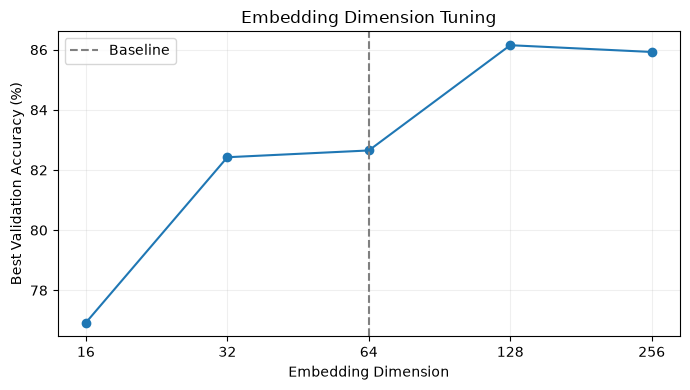

In [13]:
# Five values to test; change this list to rerun only this section.
EMBEDDING_VALUES = [16, 32, 64, 128, 256]

# Train four non-baseline models, reusing the shared baseline result.
sweep_results["embedding_dim"], sweep_histories["embedding_dim"] = run_sweep(
    "embedding_dim", EMBEDDING_VALUES
)

# Updated tuning results invalidate any previously fitted combination/final model.
combination_results = None
final_model = None

# Display a small results table and a standard accuracy trend plot.
display(sweep_results["embedding_dim"][["embedding_dim", "train_accuracy", "val_accuracy", "val_loss", "best_epoch"]])
plot_sweep("embedding_dim", EMBEDDING_VALUES, sweep_results["embedding_dim"])

## Step 5B — LSTM Hidden Size Tuning [Run independently; Person 6: No need to run]

**Purpose:** How does LSTM model capacity affect classification?

**To change this experiment:** Edit only `HIDDEN_VALUES` in the next cell, then run that cell again. You do not need to run Steps 5A–5D in order or rerun other sweeps. All other hyperparameters stay at the same baseline settings.

**Person 6:** No need to run this section; the saved table and plot can be reviewed directly.


Training LSTM Hidden Size = 16
Epoch 1/5 | train acc 0.295, val acc 0.387, train loss 1.378, val loss 1.346
Epoch 2/5 | train acc 0.402, val acc 0.512, train loss 1.309, val loss 1.210
Epoch 3/5 | train acc 0.551, val acc 0.678, train loss 1.070, val loss 0.833
Epoch 4/5 | train acc 0.689, val acc 0.756, train loss 0.787, val loss 0.653
Epoch 5/5 | train acc 0.768, val acc 0.787, train loss 0.627, val loss 0.580

Training LSTM Hidden Size = 32
Epoch 1/5 | train acc 0.349, val acc 0.476, train loss 1.350, val loss 1.262
Epoch 2/5 | train acc 0.575, val acc 0.698, train loss 1.036, val loss 0.795
Epoch 3/5 | train acc 0.736, val acc 0.771, train loss 0.700, val loss 0.645
Epoch 4/5 | train acc 0.798, val acc 0.809, train loss 0.559, val loss 0.564
Epoch 5/5 | train acc 0.830, val acc 0.822, train loss 0.473, val loss 0.556

Training LSTM Hidden Size = 128
Epoch 1/5 | train acc 0.455, val acc 0.668, train loss 1.190, val loss 0.825
Epoch 2/5 | train acc 0.715, val acc 0.780, train loss 0

,hidden_dim,train_accuracy,val_accuracy,val_loss,best_epoch
0,16,0.76765,0.78750,0.580386,5
1,32,0.83035,0.82175,0.555655,5
2,64,0.85310,0.82650,0.550090,5
3,128,0.86790,0.85425,0.445350,5
4,256,0.86570,0.85600,0.421784,5


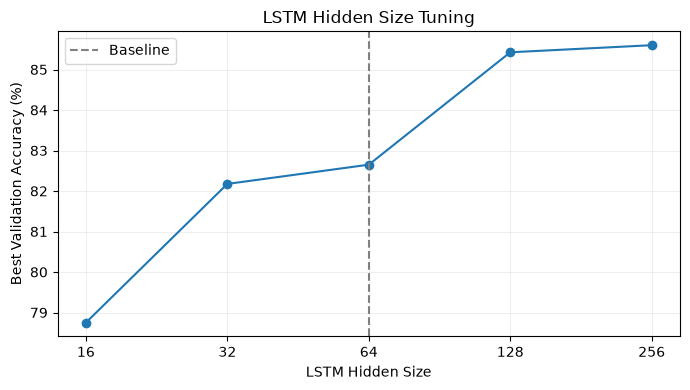

In [14]:
# Five values to test; change this list to rerun only this section.
HIDDEN_VALUES = [16, 32, 64, 128, 256]

# Train four non-baseline models, reusing the shared baseline result.
sweep_results["hidden_dim"], sweep_histories["hidden_dim"] = run_sweep(
    "hidden_dim", HIDDEN_VALUES
)

# Updated tuning results invalidate any previously fitted combination/final model.
combination_results = None
final_model = None

# Display a small results table and a standard accuracy trend plot.
display(sweep_results["hidden_dim"][["hidden_dim", "train_accuracy", "val_accuracy", "val_loss", "best_epoch"]])
plot_sweep("hidden_dim", HIDDEN_VALUES, sweep_results["hidden_dim"])

## Step 5C — **Shared Input + Output Dropout Rate** Tuning [Run independently]

**Question:** How does the **same value of p applied at two distinct positions** affect validation performance?

- **Input Dropout** acts on the embedded token features before the bidirectional LSTM.
- **Output Dropout** acts on the concatenated forward/backward final hidden state before the classifier.
- Each dropout module generates its own random mask, but both use the **single tuned `dropout` rate**.
- The five evenly spaced candidates are **`[0.0, 0.125, 0.25, 0.375, 0.5]`**, with a **baseline of `0.25`**. The same candidate rate is applied at both Dropout positions, using independently drawn masks. These values are experimental candidates, not claimed optima.

**Person 6:** You can read the saved table, figures, and exported handoff package after Person 5 executes this notebook. No model training is needed to inspect them.



Training Dropout Rate = 0
Epoch 1/5 | train acc 0.471, val acc 0.678, train loss 1.182, val loss 0.818
Epoch 2/5 | train acc 0.765, val acc 0.799, train loss 0.625, val loss 0.557
Epoch 3/5 | train acc 0.853, val acc 0.816, train loss 0.413, val loss 0.520
Epoch 4/5 | train acc 0.894, val acc 0.844, train loss 0.309, val loss 0.445
Epoch 5/5 | train acc 0.923, val acc 0.846, train loss 0.235, val loss 0.441

Training Dropout Rate = 0.125
Epoch 1/5 | train acc 0.430, val acc 0.634, train loss 1.244, val loss 0.903
Epoch 2/5 | train acc 0.728, val acc 0.774, train loss 0.708, val loss 0.610
Epoch 3/5 | train acc 0.821, val acc 0.809, train loss 0.494, val loss 0.541
Epoch 4/5 | train acc 0.862, val acc 0.828, train loss 0.388, val loss 0.503
Epoch 5/5 | train acc 0.887, val acc 0.846, train loss 0.328, val loss 0.465

Training Dropout Rate = 0.375
Epoch 1/5 | train acc 0.343, val acc 0.472, train loss 1.349, val loss 1.217
Epoch 2/5 | train acc 0.596, val acc 0.689, train loss 0.971, va

,dropout,train_accuracy,val_accuracy,val_loss,best_epoch
0,0.000,0.92255,0.84625,0.440925,5
1,0.125,0.88680,0.84550,0.465232,5
2,0.250,0.85310,0.82650,0.550090,5
3,0.375,0.81635,0.81500,0.619733,5
4,0.500,0.76710,0.76775,0.794037,5


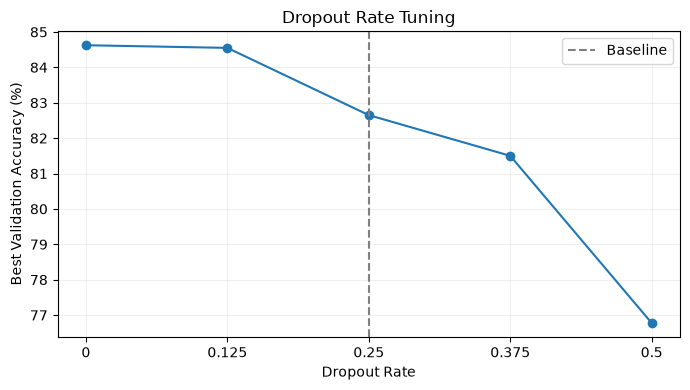

In [15]:
# Five values to test; change this list to rerun only this section.
DROPOUT_VALUES = [0.0, 0.125, 0.25, 0.375, 0.5]

# Train four non-baseline models, reusing the shared baseline result.
sweep_results["dropout"], sweep_histories["dropout"] = run_sweep(
    "dropout", DROPOUT_VALUES
)

# Updated tuning results invalidate any previously fitted combination/final model.
combination_results = None
final_model = None

# Display a small results table and a standard accuracy trend plot.
display(sweep_results["dropout"][["dropout", "train_accuracy", "val_accuracy", "val_loss", "best_epoch"]])
plot_sweep("dropout", DROPOUT_VALUES, sweep_results["dropout"])

## Step 5D — Learning Rate Tuning [Run independently; Person 6: No need to run]

**Purpose:** How does the optimizer learning rate affect convergence within five epochs?

**To change this experiment:** Edit only `LEARNING_RATE_VALUES` in the next cell, then run that cell again. You do not need to run Steps 5A–5D in order or rerun other sweeps. All other hyperparameters stay at the same baseline settings.

**Person 6:** No need to run this section; the saved table and plot can be reviewed directly.


Training Learning Rate = 0.000316228
Epoch 1/5 | train acc 0.294, val acc 0.387, train loss 1.379, val loss 1.359
Epoch 2/5 | train acc 0.404, val acc 0.475, train loss 1.328, val loss 1.230
Epoch 3/5 | train acc 0.540, val acc 0.627, train loss 1.093, val loss 0.926
Epoch 4/5 | train acc 0.653, val acc 0.702, train loss 0.863, val loss 0.761
Epoch 5/5 | train acc 0.718, val acc 0.732, train loss 0.724, val loss 0.744

Training Learning Rate = 0.00316228
Epoch 1/5 | train acc 0.543, val acc 0.766, train loss 1.036, val loss 0.617
Epoch 2/5 | train acc 0.814, val acc 0.837, train loss 0.520, val loss 0.508
Epoch 3/5 | train acc 0.875, val acc 0.862, train loss 0.364, val loss 0.439
Epoch 4/5 | train acc 0.903, val acc 0.856, train loss 0.283, val loss 0.491
Epoch 5/5 | train acc 0.920, val acc 0.876, train loss 0.229, val loss 0.432

Training Learning Rate = 0.01
Epoch 1/5 | train acc 0.649, val acc 0.839, train loss 0.837, val loss 0.468
Epoch 2/5 | train acc 0.877, val acc 0.876, tra

,learning_rate,train_accuracy,val_accuracy,val_loss,best_epoch
0,0.000316,0.71785,0.73200,0.744038,5
1,0.001000,0.85310,0.82650,0.550090,5
2,0.003162,0.91975,0.87575,0.431540,5
3,0.010000,0.94180,0.88675,0.389120,4
4,0.031623,0.85680,0.85225,0.470626,2


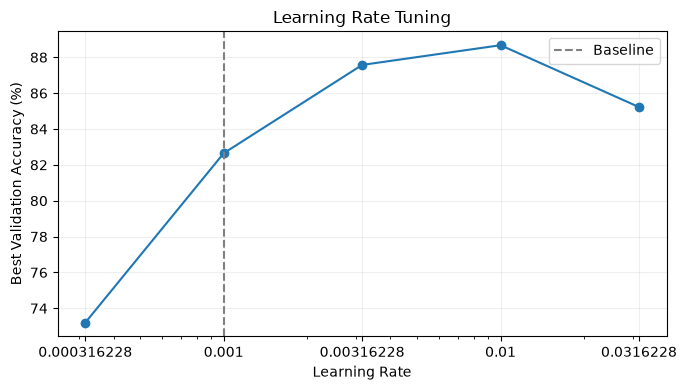

In [16]:
# Five values to test; change this list to rerun only this section.
LEARNING_RATE_VALUES = np.logspace(-3.5, -1.5, 5).tolist()

# Train four non-baseline models, reusing the shared baseline result.
sweep_results["learning_rate"], sweep_histories["learning_rate"] = run_sweep(
    "learning_rate", LEARNING_RATE_VALUES
)

# Updated tuning results invalidate any previously fitted combination/final model.
combination_results = None
final_model = None

# Display a small results table and a standard accuracy trend plot.
display(sweep_results["learning_rate"][["learning_rate", "train_accuracy", "val_accuracy", "val_loss", "best_epoch"]])
plot_sweep("learning_rate", LEARNING_RATE_VALUES, sweep_results["learning_rate"])

## Step 6 — Summarize Completed Sweeps [No training; Person 6: Can view saved results]

**Purpose:** Combine whichever of the four sweeps you have already run into one summary table. You can run this section at any time after at least one Step 5 experiment.

**Important:** If you change any Step 5 values, rerun **that** Step 5 cell and then rerun this summary. No other sweeps need to be retrained.

,Hyperparameter,Best Tested Value,Best Validation Accuracy (%)
0,Embedding Dimension,128.00,86.15
1,LSTM Hidden Size,256.00,85.60
2,Dropout Rate,0.00,84.62
3,Learning Rate,0.01,88.68


Completed sweeps: 4/4


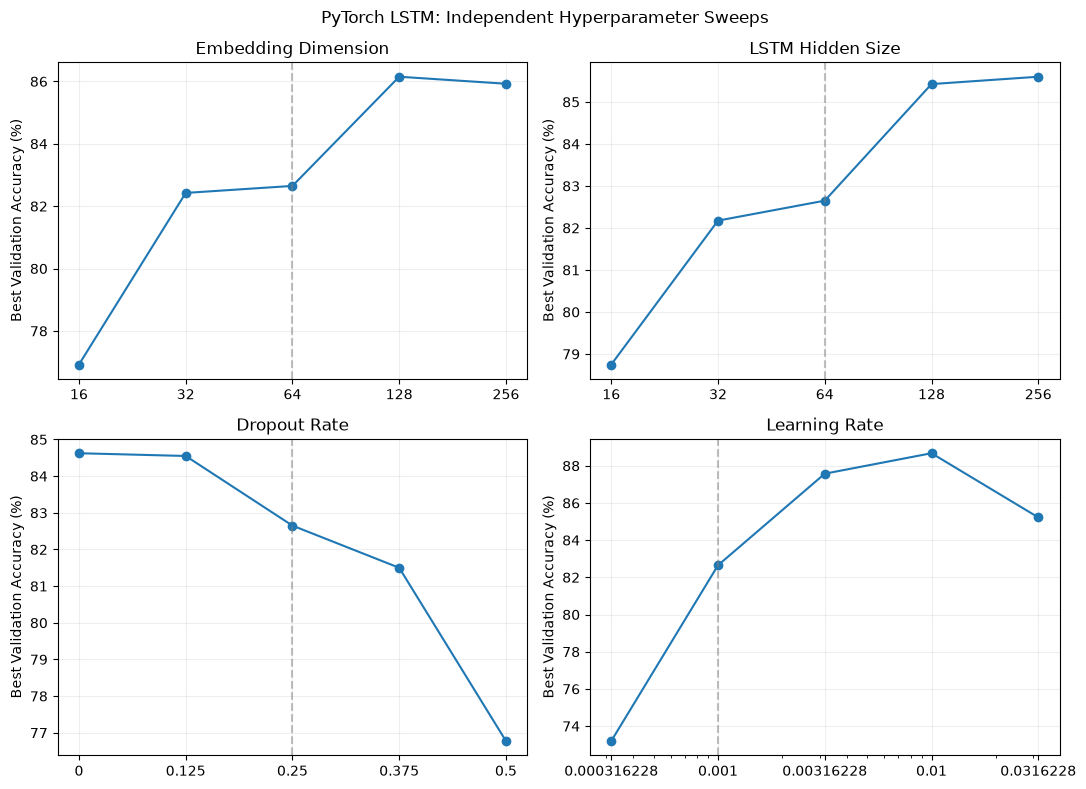

In [17]:
# Summary only: no model training occurs here.
if sweep_results:
    best_per_parameter = []
    for parameter, result in sweep_results.items():
        winner = result.sort_values(
            ["val_accuracy", "val_loss"], ascending=[False, True]
        ).iloc[0]
        best_per_parameter.append({
            "Hyperparameter": PARAMETER_LABELS[parameter],
            "Best Tested Value": winner[parameter],
            "Best Validation Accuracy (%)": round(winner["val_accuracy"] * 100, 2),
        })
    display(pd.DataFrame(best_per_parameter))
    print(f"Completed sweeps: {len(sweep_results)}/4")
else:
    print("Run any Step 5 tuning section first.")

# Optional presentation overview: four plots in one figure, without retraining.
if len(sweep_results) == 4:
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for ax, parameter in zip(axes.flat, PARAMETER_LABELS):
        result = sweep_results[parameter]
        ax.plot(result[parameter], result["val_accuracy"] * 100, marker="o")
        ax.axvline(BASELINE[parameter], linestyle="--", color="gray", alpha=0.5)
        if parameter in ("embedding_dim", "hidden_dim"):
            ax.set_xscale("log", base=2)
        elif parameter == "learning_rate":
            ax.set_xscale("log")
        values = result[parameter].tolist()
        ax.set_xticks(values)
        ax.set_xticklabels([f"{v:g}" for v in values])
        ax.set(title=PARAMETER_LABELS[parameter], ylabel="Best Validation Accuracy (%)")
        ax.grid(alpha=0.2)
    plt.suptitle("PyTorch LSTM: Independent Hyperparameter Sweeps")
    plt.tight_layout()
    plt.show()


## Step 7 — Optional Parameter Combinations [Optional training; Person 6: No need to run]

**Purpose:** Test whether promising settings from different sweeps also work well when combined. This section trains up to **three additional models** on the tuning subset.

- First run all of Steps 5A–5D.
- **This is optional** for sensitivity plots. If you change any individual sweep, rerun this cell if you want combination results to reflect that change.
- Select combinations by Validation Accuracy; never use Test Accuracy for model selection.

In [18]:
# Optional training section; run it only after all four parameter sweeps.
required_parameters = list(PARAMETER_LABELS)
if not all(p in sweep_results for p in required_parameters):
    print("Skipped: complete all four Step 5 sweeps before testing combinations.")
else:
    # Select each parameter's best observed value (ties broken by validation loss).
    best_values = {}
    for parameter in required_parameters:
        row = sweep_results[parameter].sort_values(
            ["val_accuracy", "val_loss"], ascending=[False, True]
        ).iloc[0]
        best_values[parameter] = row[parameter]

    combo_specs = [
        ("Embedding + Hidden", ["embedding_dim", "hidden_dim"]),
        ("Dropout + Learning Rate", ["dropout", "learning_rate"]),
        ("All four alternatives", required_parameters),
    ]
    combination_rows = []
    for name, selected_parameters in combo_specs:
        config = BASELINE.copy()
        for parameter in selected_parameters:
            value = best_values[parameter]
            config[parameter] = (int(value) if parameter in ("embedding_dim", "hidden_dim")
                                 else float(value))
        config["name"] = name
        print("\nTraining combination:", name)
        model, history, best, info = train_model(
            config, tune_train_ds, tune_val_ds, epochs=TUNE_EPOCHS
        )
        combination_rows.append({
            **config, "val_accuracy": best["val_accuracy"],
            "val_loss": best["val_loss"], "best_epoch": info["best_epoch"]
        })
        del model

    combination_results = pd.DataFrame(combination_rows)
    display(combination_results)


Training combination: Embedding + Hidden
Epoch 1/5 | train acc 0.556, val acc 0.750, train loss 1.034, val loss 0.690
Epoch 2/5 | train acc 0.789, val acc 0.822, train loss 0.572, val loss 0.506
Epoch 3/5 | train acc 0.852, val acc 0.850, train loss 0.411, val loss 0.452
Epoch 4/5 | train acc 0.885, val acc 0.858, train loss 0.323, val loss 0.467
Epoch 5/5 | train acc 0.905, val acc 0.872, train loss 0.262, val loss 0.415

Training combination: Dropout + Learning Rate
Epoch 1/5 | train acc 0.710, val acc 0.857, train loss 0.728, val loss 0.415
Epoch 2/5 | train acc 0.910, val acc 0.871, train loss 0.267, val loss 0.388
Epoch 3/5 | train acc 0.961, val acc 0.865, train loss 0.119, val loss 0.449
Epoch 4/5 | train acc 0.985, val acc 0.868, train loss 0.051, val loss 0.545
Epoch 5/5 | train acc 0.993, val acc 0.866, train loss 0.023, val loss 0.599

Training combination: All four alternatives
Epoch 1/5 | train acc 0.723, val acc 0.863, train loss 0.703, val loss 0.413
Epoch 2/5 | train a

,embedding_dim,hidden_dim,dropout,learning_rate,name,val_accuracy,val_loss,best_epoch
0,128,256,0.25,0.001,Embedding + Hidden,0.87225,0.415323,5
1,64,64,0.00,0.010,Dropout + Learning Rate,0.87075,0.387512,2
2,128,256,0.00,0.010,All four alternatives,0.87325,0.547475,4


## Step 8 — Final BiLSTM Training [Run after all four sweeps]

Select the best **observed validation** configuration among the 17 distinct OFAT candidates and, if completed, the three combination tests. Train a fresh **1-layer bidirectional LSTM with input/output dropout** on the full 108,000 Training Articles and validate on the 12,000 held-out Validation Articles for 5 epochs.

The saved weights correspond to the **best validation checkpoint** over the five epochs, not necessarily the last epoch; do not call this early stopping (all epochs are trained). Test data are not used for model selection. The results from the original unidirectional architecture are not valid for this modified model.


In [19]:
# Final training is separate from the four independent tuning sections.
if not all(p in sweep_results for p in PARAMETER_LABELS):
    print("Skipped: run all four Step 5 sweeps before selecting the final model.")
else:
    # Build a table of all tested individual configurations (one common baseline).
    all_rows = [baseline_result]
    for parameter, result in sweep_results.items():
        all_rows.extend(result[result["name"] != "Baseline"].to_dict("records"))
    candidate_results = pd.DataFrame(all_rows)

    # Add combination experiments if the user ran Step 7.
    if combination_results is not None:
        candidate_results = pd.concat(
            [candidate_results, combination_results], ignore_index=True
        )
    candidate_results = candidate_results.sort_values(
        ["val_accuracy", "val_loss"], ascending=[False, True]
    ).reset_index(drop=True)
    winner = candidate_results.iloc[0]
    winning_name = winner["name"]
    best_config = {
        "embedding_dim": int(winner["embedding_dim"]),
        "hidden_dim": int(winner["hidden_dim"]),
        "dropout": float(winner["dropout"]),
        "learning_rate": float(winner["learning_rate"]),
    }
    print("Best observed tuning configuration:", winning_name)
    print(best_config)

    test_metrics = None  # Previous test results are not valid for a newly trained model.
    FULL_EPOCHS = 5
    final_model, final_history, final_best_row, final_info = train_model(
        best_config, train_ds, val_ds, epochs=FULL_EPOCHS
    )
    print("Best validation epoch:", final_info["best_epoch"])

Best observed tuning configuration: Learning Rate = 0.01
{'embedding_dim': 64, 'hidden_dim': 64, 'dropout': 0.25, 'learning_rate': 0.01}
Epoch 1/5 | train acc 0.836, val acc 0.905, train loss 0.456, val loss 0.283
Epoch 2/5 | train acc 0.916, val acc 0.917, train loss 0.260, val loss 0.252
Epoch 3/5 | train acc 0.928, val acc 0.915, train loss 0.220, val loss 0.261
Epoch 4/5 | train acc 0.935, val acc 0.915, train loss 0.196, val loss 0.261
Epoch 5/5 | train acc 0.939, val acc 0.916, train loss 0.181, val loss 0.273
Best validation epoch: 2


## Step 9 — Final Learning Curves and Test Evaluation [Run after Step 8]

Evaluate the selected **bidirectional** model on the independent 7,600-article test set. Report Test Accuracy, Test Loss, Macro-F1, Best Validation Epoch, and the final training/validation curves. This cell does **not** train a model.

**Person 6:** Inspect the saved output, or the ZIP generated in Step 13, without running training.


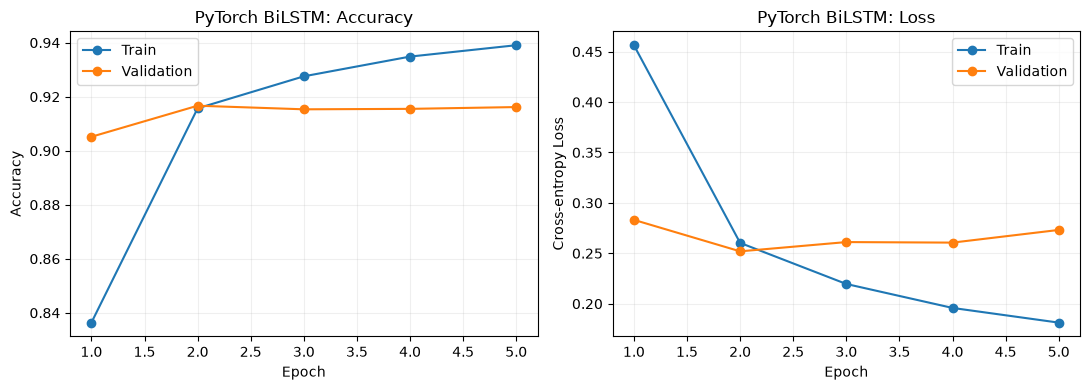

Test Accuracy: 91.37%
Test Loss: 0.2699
Macro-F1: 0.9136
Final Training Time: 538.3 seconds


In [20]:
if final_model is None:
    print("No final model in memory. Run Step 8 first, or view saved notebook outputs.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(final_history["epoch"], final_history["train_accuracy"], marker="o", label="Train")
    axes[0].plot(final_history["epoch"], final_history["val_accuracy"], marker="o", label="Validation")
    axes[0].set(title="PyTorch BiLSTM: Accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[1].plot(final_history["epoch"], final_history["train_loss"], marker="o", label="Train")
    axes[1].plot(final_history["epoch"], final_history["val_loss"], marker="o", label="Validation")
    axes[1].set(title="PyTorch BiLSTM: Loss", xlabel="Epoch", ylabel="Cross-entropy Loss")
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend()
    plt.tight_layout()
    plt.show()

    test_metrics = run_epoch(final_model, test_dl, nn.CrossEntropyLoss())
    print(f"Test Accuracy: {test_metrics['accuracy'] * 100:.2f}%")
    print(f"Test Loss: {test_metrics['loss']:.4f}")
    print(f"Macro-F1: {test_metrics['macro_f1']:.4f}")
    print(f"Final Training Time: {final_info['training_time_s']:.1f} seconds")


## Step 10 — Person 6 Handoff: How to Use the Results **Without Retraining**

**Person 5:** Finish Steps 4B–9 and Steps 11–12, then execute **Step 13 — Export Person 6 Handoff**. Save this executed `.ipynb` file and send the ZIP created by Step 13.

**Person 6:** Open the **executed** notebook and read Steps 6, 9, 11, 12, and 13, or open the ZIP directly. The ZIP contains a human-readable Markdown summary, JSON and CSV data tables, plots, class-wise test metrics, five illustrative headlines, and the best-model checkpoint. **No training is needed to read these results.**

**Interpretation:** This is an independently designed **PyTorch 1-layer BiLSTM with two dropout positions**, tuned by OFAT. It is **not** a controlled same-configuration benchmark against TensorFlow; the two notebooks can still differ in tokenization, data splits, training budgets, optimization, and other settings. Compare implementation choices and measured results without attributing all differences to the framework.

**Important:** The source notebook's previous execution outputs have been cleared because they refer to a different architecture. The export package only contains new results generated after you run this updated notebook.


## Step 11 — Person 5 Results Summary [No training; view saved output]

Displays the current run's **baseline**, all four OFAT tables (17 unique configs), optional three combination trials, selected **BiLSTM** configuration, final training history and test metrics. No model training or updates are performed here.

Run it after Steps 4–9. A later change to the architecture or a tuning range invalidates the previous final-model results and requires rerunning the affected experiments. Step 13 packages the newly run results for Person 6.


PERSON 5 — PYTORCH BiLSTM + TWO DROPOUT POSITIONS — RESULTS SUMMARY

1. Experiment Setup
Baseline hyperparameters: {'embedding_dim': 64, 'hidden_dim': 64, 'dropout': 0.25, 'learning_rate': 0.001}
Tuning samples: 20000 training / 4000 validation
Tuning epochs per model: 5

2. Baseline Result


,embedding_dim,hidden_dim,dropout,learning_rate,name,best_epoch,Train Accuracy (%),Validation Accuracy (%),train_loss,val_loss,training_time_s
0,64,64,0.25,0.001,Baseline,5,85.31,82.65,0.4074,0.5501,132.6585



3. Independent Hyperparameter Tuning

Embedding Dimension (5 tested values)


,embedding_dim,Train Accuracy (%),Validation Accuracy (%),train_loss,val_loss,best_epoch,Training Time (s)
0,16,73.12,76.92,0.6731,0.5960,5,101.9110
1,32,81.58,82.42,0.5030,0.5183,5,98.6940
2,64,85.31,82.65,0.4074,0.5501,5,132.6585
3,128,89.07,86.15,0.3167,0.4857,5,131.9864
4,256,89.40,85.92,0.3185,0.4718,4,171.3783



LSTM Hidden Size (5 tested values)


,hidden_dim,Train Accuracy (%),Validation Accuracy (%),train_loss,val_loss,best_epoch,Training Time (s)
0,16,76.76,78.75,0.6272,0.5804,5,63.3336
1,32,83.04,82.18,0.4726,0.5557,5,75.2694
2,64,85.31,82.65,0.4074,0.5501,5,132.6585
3,128,86.79,85.42,0.3712,0.4453,5,205.1826
4,256,86.57,85.60,0.3814,0.4218,5,436.9834


... (9 outputs left out)

,epoch,train_loss,Train Accuracy (%),val_loss,Validation Accuracy (%),Validation Macro-F1 (%),Accuracy Gap (pp),epoch_train_time_s
0,1,0.4564,83.64,0.2832,90.52,90.49,-6.88,111.4333
1,2,0.2603,91.57,0.2519,91.67,91.64,-0.10,108.3104
2,3,0.2196,92.75,0.2611,91.53,91.50,1.22,102.1121
3,4,0.1958,93.49,0.2606,91.55,91.49,1.94,113.4556
4,5,0.1812,93.91,0.2732,91.62,91.60,2.29,102.9436


Best validation epoch: 2
Final model training time: 538.3 seconds
(Training time excludes validation; not the total tuning time.)

7. Final Test Results


,Test Accuracy (%),Test Loss,Macro-F1,Final Training Time (s)
0,91.37,0.2699,0.9136,538.3



8. Hyperparameter Trend Plots


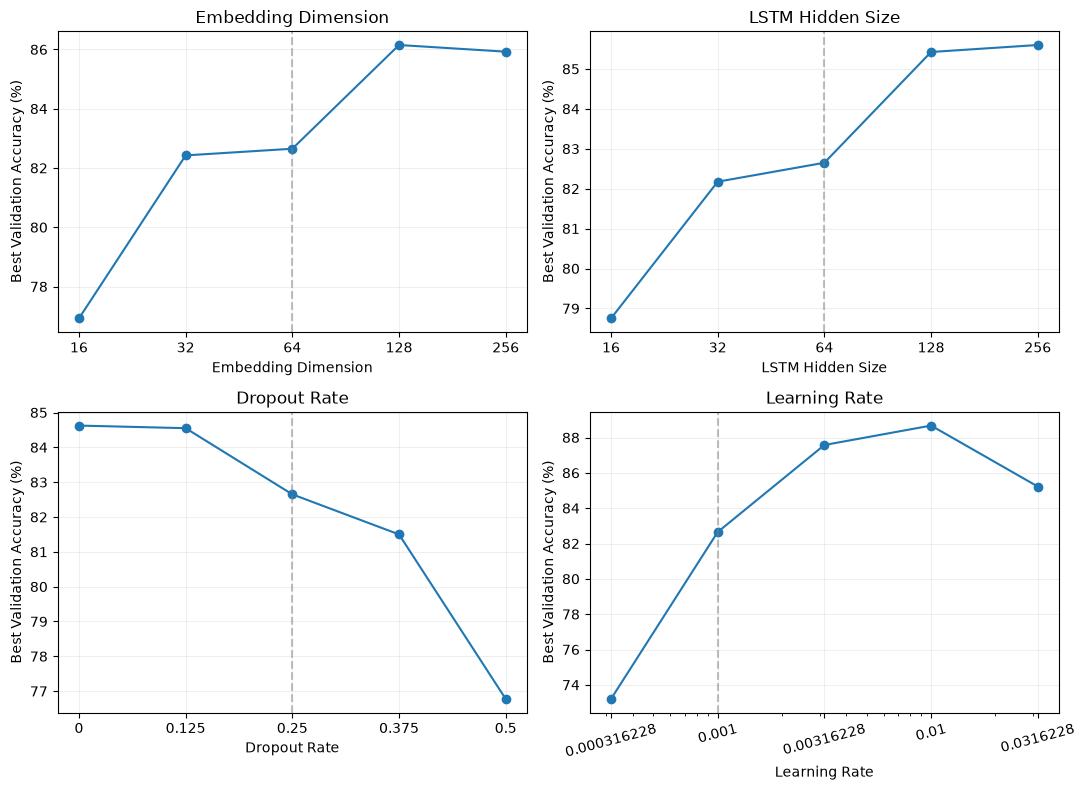


9. Final Training / Validation Learning Curves


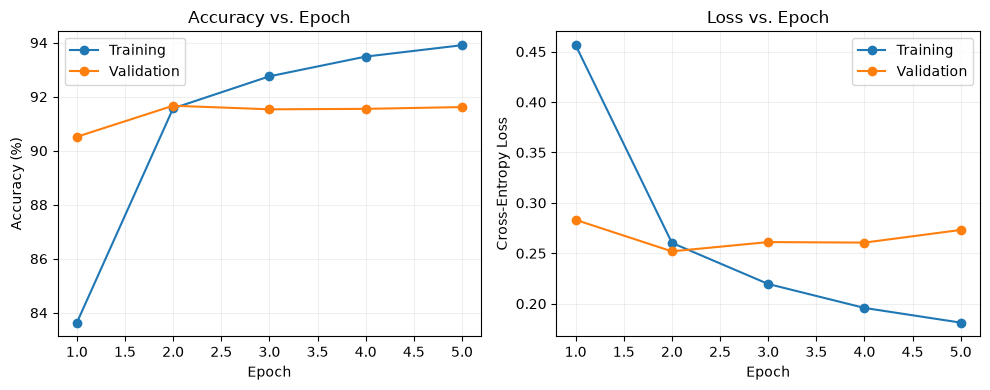

In [21]:
# Show the available Person 5 results in one place (no model training or file export).
print("PERSON 5 — PYTORCH BiLSTM + TWO DROPOUT POSITIONS — RESULTS SUMMARY")
print("=" * 48)

# 1. Shared experiment settings and baseline result
if "BASELINE" in globals():
    print("\n1. Experiment Setup")
    print("Baseline hyperparameters:", BASELINE)
    print(f"Tuning samples: {TUNE_TRAIN_SIZE} training / {TUNE_VAL_SIZE} validation")
    print(f"Tuning epochs per model: {TUNE_EPOCHS}")

if "baseline_result" in globals():
    print("\n2. Baseline Result")
    baseline_table = pd.DataFrame([baseline_result]).copy()
    for col in ["train_accuracy", "val_accuracy"]:
        baseline_table[col] = (baseline_table[col] * 100).round(2)
    display(baseline_table.rename(columns={
        "train_accuracy": "Train Accuracy (%)",
        "val_accuracy": "Validation Accuracy (%)"
    }).round(4))
else:
    print("\n2. Baseline Result: Run Step 4B first.")

# 2. Four independent hyperparameter sweeps
print("\n3. Independent Hyperparameter Tuning")
if "sweep_results" in globals() and sweep_results:
    for parameter, label in PARAMETER_LABELS.items():
        if parameter not in sweep_results:
            print(f"\n{label}: not yet run (Step 5).")
            continue
        results = sweep_results[parameter].copy()
        print(f"\n{label} ({len(results)} tested values)")
        cols = [parameter, "train_accuracy", "val_accuracy", "train_loss",
                "val_loss", "best_epoch", "training_time_s"]
        shown = results[cols].copy()
        shown["train_accuracy"] = (shown["train_accuracy"] * 100).round(2)
        shown["val_accuracy"] = (shown["val_accuracy"] * 100).round(2)
        display(shown.rename(columns={
            "train_accuracy": "Train Accuracy (%)",
            "val_accuracy": "Validation Accuracy (%)",
            "training_time_s": "Training Time (s)"
        }).round(4))

    # Combine the completed sweeps without repeating the shared baseline.
    if "baseline_result" in globals():
        all_rows = [baseline_result.copy()]
        for parameter, results in sweep_results.items():
            all_rows.extend(results.loc[results["name"] != "Baseline"].to_dict("records"))
        tested = pd.DataFrame(all_rows)
        tested = tested.sort_values(["val_accuracy", "val_loss"], ascending=[False, True])
        print(f"\nUnique configurations tested (OFAT): {len(tested)}")
        print("Top five OFAT configurations (ranked by validation accuracy):")
        top = tested[["name", "embedding_dim", "hidden_dim", "dropout",
                      "learning_rate", "val_accuracy", "val_loss"]].head(5).copy()
        top["val_accuracy"] = (top["val_accuracy"] * 100).round(2)
        display(top.rename(columns={"val_accuracy": "Validation Accuracy (%)"}).round(5))
else:
    print("No sweep results available yet. Run any Step 5 section to populate them.")

# 3. Optional parameter combinations and the selected final configuration
print("\n4. Combination Experiments")
if "combination_results" in globals() and combination_results is not None:
    combinations = combination_results.copy()
    combinations["val_accuracy"] = (combinations["val_accuracy"] * 100).round(2)
    display(combinations.rename(columns={"val_accuracy": "Validation Accuracy (%)"}).round(5))
else:
    print("Not available (Step 7 is optional).")

print("\n5. Selected Final Configuration")
if "final_model" in globals() and final_model is not None and "best_config" in globals():
    print("Selected from validation results:", best_config)
    if "winning_name" in globals():
        print("Winning tuning experiment:", winning_name)
else:
    print("No current final model. Complete Step 8 to select and train one.")

# 4. Final full-dataset training and test results
print("\n6. Final Training History")
if "final_model" in globals() and final_model is not None and "final_history" in globals():
    history = final_history.copy()
    for col in ["train_accuracy", "val_accuracy", "val_macro_f1", "accuracy_gap"]:
        history[col] = (history[col] * 100).round(2)
    display(history.rename(columns={
        "train_accuracy": "Train Accuracy (%)",
        "val_accuracy": "Validation Accuracy (%)",
        "val_macro_f1": "Validation Macro-F1 (%)",
        "accuracy_gap": "Accuracy Gap (pp)"
    }).round(4))
    print("Best validation epoch:", final_info["best_epoch"])
    print(f"Final model training time: {final_info['training_time_s']:.1f} seconds")
    print("(Training time excludes validation; not the total tuning time.)")
else:
    print("Not available (Step 8 has not produced a current final model).")

print("\n7. Final Test Results")
if ("final_model" in globals() and final_model is not None
        and "test_metrics" in globals() and test_metrics is not None):
    final_summary = pd.DataFrame([{
        "Test Accuracy (%)": round(test_metrics["accuracy"] * 100, 2),
        "Test Loss": round(test_metrics["loss"], 4),
        "Macro-F1": round(test_metrics["macro_f1"], 4),
        "Final Training Time (s)": round(final_info["training_time_s"], 1),
    }])
    display(final_summary)
else:
    print("Not available for the current final model. Complete Step 9 first.")

# 5. Display available charts without retraining anything.
if "sweep_results" in globals() and sweep_results:
    print("\n8. Hyperparameter Trend Plots")
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (parameter, label) in zip(axes.flat, PARAMETER_LABELS.items()):
        if parameter not in sweep_results:
            ax.set_title(f"{label} (not yet run)")
            ax.axis("off")
            continue
        results = sweep_results[parameter].sort_values(parameter)
        values = results[parameter].tolist()
        ax.plot(values, results["val_accuracy"] * 100, marker="o")
        ax.axvline(BASELINE[parameter], color="gray", linestyle="--", alpha=0.5)
        if parameter in ("embedding_dim", "hidden_dim"):
            ax.set_xscale("log", base=2)
        elif parameter == "learning_rate":
            ax.set_xscale("log")
        ax.set_xticks(values)
        ax.set_xticklabels([f"{v:g}" for v in values], rotation=15 if parameter == "learning_rate" else 0)
        ax.set_title(label)
        ax.set_xlabel(label)
        ax.set_ylabel("Best Validation Accuracy (%)")
        ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

if "final_model" in globals() and final_model is not None and "final_history" in globals():
    print("\n9. Final Training / Validation Learning Curves")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for phase in ["train", "val"]:
        axes[0].plot(final_history["epoch"], final_history[f"{phase}_accuracy"] * 100,
                     marker="o", label="Training" if phase == "train" else "Validation")
        axes[1].plot(final_history["epoch"], final_history[f"{phase}_loss"],
                     marker="o", label="Training" if phase == "train" else "Validation")
    axes[0].set(title="Accuracy vs. Epoch", xlabel="Epoch", ylabel="Accuracy (%)")
    axes[1].set(title="Loss vs. Epoch", xlabel="Epoch", ylabel="Cross-Entropy Loss")
    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


# Notes for Person 6 — Understanding the Independent PyTorch Results

**Run status:** This notebook was modified from the original Ver4 **unidirectional** LSTM to a **single-layer bidirectional** LSTM with two independent `nn.Dropout` positions. Original training outputs were cleared. **Scores only become valid after Person 5 executes the updated notebook and saves the outputs.**

**Architecture (PyTorch):** Token IDs → Trainable Embedding → Input Dropout(p) → Packed 1-layer Bidirectional LSTM → concatenate final Forward and Backward Hidden States → Output Dropout(p) → Linear(2H,4) → raw class logits. The two dropout masks are independent but both probabilities are controlled by one hyperparameter `p`.

**Four OFAT axes (original Embedding/Hidden/Learning-Rate ranges; revised Dropout range):**

- Embedding: `[16,32,64,128,256]`
- Hidden Size (per direction): `[16,32,64,128,256]`
- Shared input/output Dropout: `[0.0,0.125,0.25,0.375,0.5]` (baseline `0.25`)
- Adam Learning Rate: `np.logspace(-3.5,-1.5,5)`

**Experimental method:** Same 20,000 training and 4,000 validation subset, 5 epochs per candidate; baseline reused across four sweeps so 17 distinct OFAT candidates, then three optional combinations. Final training uses 108,000 Train / 12,000 Validation for five epochs and evaluates on the untouched 7,600 Test Set using the validation-selected checkpoint.

**Where to find results without running anything:**

1. Step 6 — OFAT summary tables.
2. Step 9 — final learning curves, Test Accuracy, Test Loss, Macro-F1, training time.
3. Step 11 — combined results and plots.
4. Step 12 — per-class test recall and five paraphrased headline predictions; example headlines are **unlabeled illustrations**, not part of test accuracy.
5. **Step 13 — ZIP and summary files generated by the final export cell**. This is the preferred handoff.

**Scientific limitations:** TensorFlow and PyTorch notebook results are independent full-pipeline comparisons, not an isolated test of the framework. Note that this PyTorch notebook builds vocabulary from the original full training split before its 10% validation partition (word-frequency information from validation text can enter the vocabulary, not the validation labels). The OFAT tuning is limited by tested ranges, interactions and a single random seed. The held-out test set must not be used for tuning.


## Step 12 — Test Performance by Class and Five Shared Headlines

This section recomputes predictions **only using the newly trained BiLSTM**:

1. **Per-class recall** (correctly classified articles within each true AG News category) from 7,600 labeled test articles.
2. **Five shared paraphrased illustrative headlines** classified with the actual trained PyTorch model. These headline inputs are **not labeled test examples**, so their Softmax scores cannot be used for Test Accuracy.

Requires Step 8 final training; Step 9 test metrics are reused when present. The exported figure and prediction CSV are included in Step 13's ZIP. If TensorFlow used different wording, its input strings must be aligned before drawing per-headline conclusions.


Per-class recall (also called class-wise accuracy):
     World: 89.6%
    Sports: 97.9%
  Business: 88.3%
  Sci/Tech: 89.6%
Overall test accuracy: 91.37%


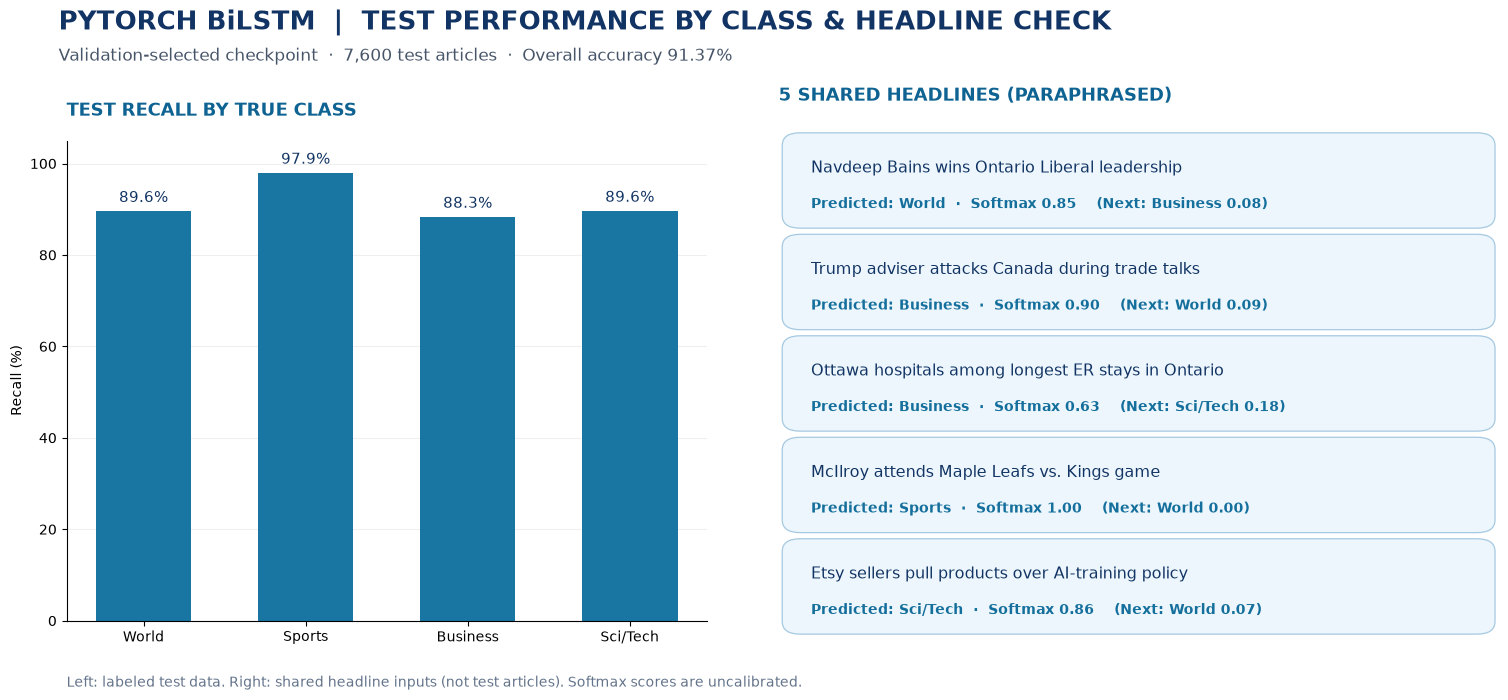

Saved: PyTorch_BiLSTM_Test_Per_Class_and_Headline_Check.png


In [22]:
# Step 12 — NEW PyTorch BiLSTM class-level test results + illustrative headlines
# Run AFTER Step 8 in the same live kernel so final_model contains trained weights.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.metrics import confusion_matrix
from torch.nn.utils.rnn import pad_sequence
import textwrap

if "final_model" not in globals() or final_model is None:
    raise RuntimeError("First run the setup and Step 8 — Final Model Training in this kernel.")

# A. Calculate each test class's recall using TRUE and PREDICTED test labels.
# If Step 9 has already run, reuse its results; no second evaluation is needed.
if "test_metrics" not in globals() or test_metrics is None:
    test_metrics = run_epoch(final_model, test_dl, nn.CrossEntropyLoss())

true_test_labels = np.asarray(test_metrics["labels"])
predicted_test_labels = np.asarray(test_metrics["predictions"])
test_confusion_matrix = confusion_matrix(
    true_test_labels, predicted_test_labels, labels=list(range(N_CLASSES))
)
per_class_recall = 100 * np.divide(
    np.diag(test_confusion_matrix),
    test_confusion_matrix.sum(axis=1),
    out=np.zeros(N_CLASSES, dtype=float),
    where=test_confusion_matrix.sum(axis=1) > 0,
)

print("Per-class recall (also called class-wise accuracy):")
for class_name, recall in zip(CLASSES, per_class_recall):
    print(f"  {class_name:>8}: {recall:.1f}%")
print(f"Overall test accuracy: {test_metrics['accuracy'] * 100:.2f}%")

# B. Classify the five shared PARAPHRASED illustrative headlines in the same order.
# Check wording against the TensorFlow notebook before claiming identical inputs.
# These are illustrative inputs, not labeled AG News test articles.
# Softmax outputs come from this PyTorch model, not from the TensorFlow slide.
HEADLINES = [
    'Navdeep Bains wins Ontario Liberal leadership',
    'Trump adviser attacks Canada during trade talks',
    'Ottawa hospitals among longest ER stays in Ontario',
    'McIlroy attends Maple Leafs vs. Kings game',
    'Etsy sellers pull products over AI-training policy',
]

# Apply EXACTLY the same tokenizer, training vocabulary, and truncation limit.
headline_token_ids = [encode(text, stoi, MAX_LEN) for text in HEADLINES]
headline_lengths = torch.tensor([len(ids) for ids in headline_token_ids], dtype=torch.long)
headline_batch = pad_sequence(
    [torch.tensor(ids, dtype=torch.long) for ids in headline_token_ids],
    batch_first=True, padding_value=PAD_IDX,
).to(device)

final_model.eval()  # Evaluation mode disables Dropout.
with torch.inference_mode():
    headline_logits = final_model(headline_batch, headline_lengths)
    headline_softmax = torch.softmax(headline_logits, dim=1).cpu().numpy()

# C. Presentation-ready figure (real model outputs, no hard-coded scores).
fig = plt.figure(figsize=(16, 7.5), facecolor="white")
fig.text(0.055, 0.955, "PYTORCH BiLSTM  |  TEST PERFORMANCE BY CLASS & HEADLINE CHECK",
         fontsize=19, fontweight="bold", color="#123464", va="top")
fig.text(0.055, 0.904,
         f"Validation-selected checkpoint  ·  {len(true_test_labels):,} test articles  ·  "
         f"Overall accuracy {test_metrics['accuracy'] * 100:.2f}%",
         fontsize=12, color="#475569", va="top")

left_ax = fig.add_axes([0.060, 0.14, 0.40, 0.64])
bars = left_ax.bar(range(N_CLASSES), per_class_recall, width=0.59,
                   color="#1976A3")
left_ax.set_title("TEST RECALL BY TRUE CLASS", loc="left",
                  fontsize=13, fontweight="bold", color="#0E6392", pad=18)
left_ax.set_xticks(range(N_CLASSES), CLASSES)
left_ax.set_ylim(0, 105)
left_ax.set_ylabel("Recall (%)")
left_ax.grid(axis="y", alpha=0.20)
left_ax.set_axisbelow(True)
left_ax.spines[["top", "right"]].set_visible(False)
for bar, recall in zip(bars, per_class_recall):
    left_ax.text(bar.get_x() + bar.get_width()/2, recall + 1.2,
                 f"{recall:.1f}%", ha="center", va="bottom",
                 fontsize=11, color="#123464")

right_ax = fig.add_axes([0.505, 0.12, 0.45, 0.68])
right_ax.set_xlim(0, 1)
right_ax.set_ylim(0, 1)
right_ax.axis("off")
right_ax.set_title("5 SHARED HEADLINES (PARAPHRASED)",
                   loc="left", fontsize=13, fontweight="bold",
                   color="#0E6392", pad=18)

for i, (headline, probabilities) in enumerate(zip(HEADLINES, headline_softmax)):
    y = 0.804 - i * 0.199
    card = FancyBboxPatch((0.01, y), 0.98, 0.177,
                          boxstyle="round,pad=0.005,rounding_size=0.025",
                          linewidth=0.9, edgecolor="#A6C9E1", facecolor="#ECF6FC")
    right_ax.add_patch(card)
    right_ax.text(0.045, y + 0.113, textwrap.fill(headline, width=53),
                  fontsize=11.2, color="#123464", va="center", linespacing=1.1)
    highest = int(np.argmax(probabilities))
    runner_up = int(np.argsort(probabilities)[-2])
    caption = (f"Predicted: {CLASSES[highest]}  ·  Softmax {probabilities[highest]:.2f}"
               f"    (Next: {CLASSES[runner_up]} {probabilities[runner_up]:.2f})")
    right_ax.text(0.045, y + 0.042, caption,
                  fontsize=9.8, fontweight="bold", color="#156F9C", va="center")

fig.text(0.06, 0.052,
         "Left: labeled test data. Right: shared headline inputs (not test articles). "
         "Softmax scores are uncalibrated.",
         fontsize=10, color="#64748B")

output_filename = "PyTorch_BiLSTM_Test_Per_Class_and_Headline_Check.png"
fig.savefig(output_filename, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {output_filename}")



## Step 13 — **Export Complete Results for Person 6 (No Retraining)**

**Run this once, after Steps 8, 9, and 12 have completed with the NEW BiLSTM model.** It performs no training. It writes a standalone, self-contained results package:

- `person6_bilstm_results/README_Person6.md`: clear English explanation, actual best hyperparameters, all four tuning winners, real validation and test results, per-class metrics, and what can/cannot be inferred.
- `person6_bilstm_results/summary.json`: structured run metadata, all tested configurations, metrics and predictions.
- CSVs: `ofat_all_results.csv`, individual sweep CSVs, best-of-sweep table, optional combinations, final learning curve, class-level metrics, confusion matrix, per-article test predictions, and five headline predictions.
- PNGs: four tuning plots, final learning curves, test confusion matrix, class recall, and the figure from Step 12 (if available).
- `best_bilstm_checkpoint.pt`: validation-selected model weights and reconstruction metadata (optional if Person 6 only presents saved results).
- **`pytorch_bilstm_ver4_person6_handoff.zip`**: a single ZIP for transfer.

After running, **save the executed Notebook** so Person 6 can see saved cell outputs without rerunning. The ZIP may be shared separately; it does not need the original training environment to read the Markdown/CSV/PNG files.

**Run-time guard:** The cell checks that the four sweeps and final test metrics exist; otherwise it stops rather than exporting a misleading partial result.


In [23]:

# Step 13 — Export a complete self-contained package for Person 6 (NO training)
from pathlib import Path
import json
import shutil
import platform
from datetime import datetime, timezone
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from IPython.display import Markdown, display

# Export ONLY after the modified BiLSTM has been trained and evaluated.
if not all(p in sweep_results for p in PARAMETER_LABELS):
    raise RuntimeError("Run all four NEW BiLSTM Step 5 sweeps before exporting.")
if ("final_model" not in globals() or final_model is None or
        "final_history" not in globals() or
        "test_metrics" not in globals() or test_metrics is None or
        "best_config" not in globals()):
    raise RuntimeError("Run NEW BiLSTM final training and test evaluation (Steps 8–9) first.")
if not (final_model.lstm.bidirectional and final_model.lstm.num_layers == 1 and
        hasattr(final_model, "input_dropout") and hasattr(final_model, "output_dropout")):
    raise RuntimeError("Unexpected architecture; do NOT export results from another model.")

EXPORT_DIR = Path("person6_bilstm_ver4_results")
EXPORT_DIR.mkdir(exist_ok=True)

# Small helper so pandas/numpy/pytorch scalar values can be serialized to JSON.
def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (np.integer, np.floating, np.bool_)):
        return value.item()
    if isinstance(value, float):
        return value if np.isfinite(value) else None
    return value

# 1. Save every OFAT candidate once (shared baseline appears only once).
all_ofat_rows = [baseline_result.copy()]
best_sweep_rows = []
for parameter, label in PARAMETER_LABELS.items():
    tbl = sweep_results[parameter].copy()
    tbl.to_csv(EXPORT_DIR / f"sweep_{parameter}.csv", index=False)
    # Each sweep has the reused baseline, so remove duplicates from aggregate.
    all_ofat_rows.extend(tbl.loc[tbl["name"] != "Baseline"].to_dict("records"))
    w = tbl.sort_values(["val_accuracy", "val_loss"], ascending=[False, True]).iloc[0]
    best_sweep_rows.append({
        "parameter": parameter, "label": label, "selected_value": w[parameter],
        "val_accuracy": w["val_accuracy"], "val_loss": w["val_loss"],
        "best_epoch": w["best_epoch"],
    })
ofat_table = pd.DataFrame(all_ofat_rows).sort_values(
    ["val_accuracy", "val_loss"], ascending=[False, True]
).reset_index(drop=True)
ofat_table.to_csv(EXPORT_DIR / "ofat_all_results.csv", index=False)
selected_sweeps = pd.DataFrame(best_sweep_rows)
selected_sweeps.to_csv(EXPORT_DIR / "best_per_sweep.csv", index=False)

if combination_results is not None:
    combination_results.to_csv(EXPORT_DIR / "combination_results.csv", index=False)

final_history.to_csv(EXPORT_DIR / "final_training_learning_curve.csv", index=False)

# 2. Save full held-out test predictions and reliable class metrics.
true_ids = np.asarray(test_metrics["labels"], dtype=int)
pred_ids = np.asarray(test_metrics["predictions"], dtype=int)
if len(true_ids) != len(test_ds):
    raise RuntimeError("Test sample count mismatch; re-run Step 9 on the held-out test loader.")
cm = confusion_matrix(true_ids, pred_ids, labels=list(range(N_CLASSES)))
precision, recall, f1, support = precision_recall_fscore_support(
    true_ids, pred_ids, labels=list(range(N_CLASSES)), zero_division=0
)
class_table = pd.DataFrame({
    "class_id": list(range(N_CLASSES)), "class_name": CLASSES,
    "precision": precision, "recall": recall, "f1": f1, "support": support,
})
class_table.to_csv(EXPORT_DIR / "class_metrics.csv", index=False)
pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(
    EXPORT_DIR / "test_confusion_matrix.csv", index_label="True Class"
)
pd.DataFrame({
    "true_class_id": true_ids, "true_class": [CLASSES[i] for i in true_ids],
    "predicted_class_id": pred_ids, "predicted_class": [CLASSES[i] for i in pred_ids],
}).to_csv(EXPORT_DIR / "test_predictions.csv", index=False)

# 3. Generate the five shared illustrative headline predictions from the trained model.
# These are not labeled test observations and are never used to calculate test accuracy.
HEADLINES_EXPORT = [
    "Navdeep Bains wins Ontario Liberal leadership",
    "Trump adviser attacks Canada during trade talks",
    "Ottawa hospitals among longest ER stays in Ontario",
    "McIlroy attends Maple Leafs vs. Kings game",
    "Etsy sellers pull products over AI-training policy",
]
headline_ids = [encode(text, stoi, MAX_LEN) for text in HEADLINES_EXPORT]
headline_lens = torch.tensor([len(ids) for ids in headline_ids], dtype=torch.long)
headline_tokens = pad_sequence(
    [torch.tensor(ids, dtype=torch.long) for ids in headline_ids],
    batch_first=True, padding_value=PAD_IDX,
).to(device)
final_model.eval()  # Both dropout locations OFF for inference.
with torch.inference_mode():
    headline_probs = torch.softmax(final_model(headline_tokens, headline_lens), dim=1).cpu().numpy()
headline_table = pd.DataFrame({
    "headline": HEADLINES_EXPORT,
    "predicted_class": [CLASSES[int(np.argmax(x))] for x in headline_probs],
    "predicted_class_probability": [float(np.max(x)) for x in headline_probs],
    **{f"prob_{CLASSES[i].replace('/', '_')}": headline_probs[:, i] for i in range(N_CLASSES)},
})
headline_table.to_csv(EXPORT_DIR / "five_headline_predictions.csv", index=False)

# 4. Save a presentation-ready 2x2 figure with original tuning axis values.
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (parameter, label) in zip(axes.flat, PARAMETER_LABELS.items()):
    data = sweep_results[parameter].sort_values(parameter)
    ax.plot(data[parameter], data["val_accuracy"] * 100, marker="o")
    ax.axvline(BASELINE[parameter], linestyle="--", linewidth=1, color="gray")
    if parameter in ("embedding_dim", "hidden_dim"):
        ax.set_xscale("log", base=2)
    elif parameter == "learning_rate":
        ax.set_xscale("log")
    ax.set_xticks(data[parameter].tolist())
    ax.set_xticklabels([f"{v:.4g}" for v in data[parameter]])
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("Best Validation Accuracy (%)")
    ax.grid(alpha=0.2)
fig.suptitle("PyTorch 1-layer BiLSTM | Four OFAT Sweeps | Two Dropout Positions")
fig.tight_layout()
fig.savefig(EXPORT_DIR / "four_hyperparameter_sweeps.png", dpi=170, bbox_inches="tight")
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for phase, label in [("train", "Train"), ("val", "Validation")]:
    axes[0].plot(final_history["epoch"], final_history[f"{phase}_accuracy"] * 100,
                 marker="o", label=label)
    axes[1].plot(final_history["epoch"], final_history[f"{phase}_loss"],
                 marker="o", label=label)
axes[0].set(title="Accuracy by Epoch", xlabel="Epoch", ylabel="Accuracy (%)")
axes[1].set(title="Cross-Entropy Loss by Epoch", xlabel="Epoch", ylabel="Loss")
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend()
fig.tight_layout()
fig.savefig(EXPORT_DIR / "final_learning_curves.png", dpi=170, bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(N_CLASSES), CLASSES, rotation=35, ha="right")
ax.set_yticks(range(N_CLASSES), CLASSES)
ax.set(xlabel="Predicted Class", ylabel="True Class", title="BiLSTM — Held-out Test Confusion Matrix")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(int(v)), ha="center", va="center",
            color="white" if v > cm.max() / 2 else "black", fontsize=10)
fig.colorbar(im, ax=ax, label="Articles")
fig.tight_layout()
fig.savefig(EXPORT_DIR / "test_confusion_matrix.png", dpi=170, bbox_inches="tight")
plt.close(fig)

# Include Step 12's original presentation figure if Step 12 was run.
step12_figure = Path("PyTorch_BiLSTM_Test_Per_Class_and_Headline_Check.png")
if step12_figure.exists():
    shutil.copy2(step12_figure, EXPORT_DIR / step12_figure.name)

# 5. Save the final selected checkpoint for optional later inference (not needed for viewing results).
param_count = sum(p.numel() for p in final_model.parameters() if p.requires_grad)
torch.save({
    "state_dict": final_model.state_dict(), "best_config": best_config,
    "vocab_size": VOCAB_SIZE, "n_classes": N_CLASSES,
    "max_len": MAX_LEN, "classes": CLASSES, "stoi": stoi,
    "architecture": "1-layer bidirectional LSTM; input/output dropout with shared p",
}, EXPORT_DIR / "best_bilstm_checkpoint.pt")

# 6. Structured summary (fully grounded in new results).
summary = {
    "status": "completed_run", "generated_utc": datetime.now(timezone.utc).isoformat(),
    "framework": "PyTorch", "task": "AG News 4-way classification",
    "architecture": {
        "num_lstm_layers": 1, "bidirectional": True,
        "dropout_placement": ["Embedding-to-LSTM", "Final-hidden-to-Linear"],
        "dropout_rates": "one shared p, independent masks at both positions",
        "lstm_built_in_dropout": 0.0,
        "final_representation_dim": 2 * int(best_config["hidden_dim"]),
        "trainable_parameter_count": param_count,
    },
    "preprocessing": {
        "dataset": "aRWA787/ag_news_dataset", "tokenizer": "custom lowercase regex",
        "vocab_size": VOCAB_SIZE, "max_len": MAX_LEN,
        "padding": "right padding, dynamic per batch; packed LSTM",
        "vocabulary_caveat": "built on all original 120k train texts before train/validation splitting",
    },
    "training": {
        "seed": SEED, "batch_size": BATCH_SIZE,
        "train_size": len(train_ds), "val_size": len(val_ds),
        "test_size": len(test_ds), "tuning_train_size": len(tune_train_ds),
        "tuning_val_size": len(tune_val_ds),
        "tune_epochs": TUNE_EPOCHS, "full_epochs": FULL_EPOCHS,
        "optimizer": "Adam", "loss_function": "CrossEntropyLoss",
        "checkpoint_selection": "best validation accuracy, validation loss tie-breaker",
        "device": str(device), "torch_version": str(torch.__version__),
        "python_version": platform.python_version(),
    },
    "search_values": {
        "embedding_dim": list(EMBEDDING_VALUES),
        "hidden_dim": list(HIDDEN_VALUES),
        "dropout": list(DROPOUT_VALUES),
        "learning_rate": list(LEARNING_RATE_VALUES),
    },
    "ofat_unique_configuration_count": len(ofat_table),
    "ofat_results": ofat_table.to_dict("records"),
    "best_per_sweep": selected_sweeps.to_dict("records"),
    "combination_results": (combination_results.to_dict("records")
                            if combination_results is not None else []),
    "selected_final_config": best_config,
    "selected_from": str(winning_name),
    "best_validation_epoch": int(final_info["best_epoch"]),
    "best_validation_accuracy": float(final_best_row["val_accuracy"]),
    "best_validation_loss": float(final_best_row["val_loss"]),
    "test_accuracy": float(test_metrics["accuracy"]),
    "test_loss": float(test_metrics["loss"]),
    "test_macro_f1": float(test_metrics["macro_f1"]),
    "final_training_time_s": float(final_info["training_time_s"]),
    "final_total_fit_time_s": float(final_info["total_fit_time_s"]),
    "class_metrics": class_table.to_dict("records"),
    "five_headline_predictions": headline_table.to_dict("records"),
    "interpretation_caveat": "Not a controlled TensorFlow-vs-PyTorch framework test.",
}
(EXPORT_DIR / "summary.json").write_text(
    json.dumps(json_safe(summary), indent=2, ensure_ascii=False), encoding="utf-8"
)

# 7. Readable markdown report for Person 6 (actual data, not placeholders).
lines = [
    "# Person 5 — PyTorch BiLSTM Results for Person 6",
    "",
    "**This file summarizes an executed model run. No training is needed to read it.**",
    "",
    "## 1. Model architecture and training setup",
    "",
    "- Task: AG News four-class text classification (World / Sports / Business / Sci/Tech)",
    "- Architecture: Embedding → Input Dropout → single-layer **Bidirectional LSTM** → ",
    "  concatenate both final directional states → Output Dropout → Linear(2H,4)",
    "- The two Dropout layers have independent random masks and share the tuned rate `p`.",
    f"- Sequence length: at most {MAX_LEN} tokens; batch size {BATCH_SIZE}; vocabulary {VOCAB_SIZE:,} tokens",
    f"- Train / Validation / Test: {len(train_ds):,} / {len(val_ds):,} / {len(test_ds):,}",
    f"- OFAT tuning: {len(tune_train_ds):,} train, {len(tune_val_ds):,} validation, {TUNE_EPOCHS} epochs per candidate",
    f"- Distinct OFAT configurations: {len(ofat_table)} (the baseline is reused); combination trials: {0 if combination_results is None else len(combination_results)}",
    f"- Final trainable parameters: {param_count:,}; device: {device}",
    "",
    "## 2. Hyperparameter search ranges (Dropout sweep revised; other ranges retained)",
    "",
    f"- Embedding Dimension: `{list(EMBEDDING_VALUES)}`",
    f"- Hidden Size per direction: `{list(HIDDEN_VALUES)}`",
    f"- Shared Input/Output Dropout: `{list(DROPOUT_VALUES)}`",
    f"- Adam Learning Rate: `{[round(float(x), 8) for x in LEARNING_RATE_VALUES]}`",
    "",
    "### Best observed value in each OFAT sweep",
    "",
    "| Parameter | Best tested value | Best validation accuracy | Best epoch |",
    "|---|---:|---:|---:|",
]
for row in best_sweep_rows:
    lines.append(f"| {row['label']} | {row['selected_value']:.7g} | {row['val_accuracy'] * 100:.2f}% | {int(row['best_epoch'])} |")
lines += [
    "", "## 3. Selected model and evaluation", "",
    f"- Selected from candidate: **{winning_name}**",
    f"- Selected hyperparameters: **{best_config}**",
    f"- Best validation checkpoint: **Epoch {final_info['best_epoch']}**",
    f"- Best validation accuracy: **{final_best_row['val_accuracy'] * 100:.2f}%**",
    f"- Best validation loss: **{final_best_row['val_loss']:.4f}**",
    f"- Held-out test accuracy: **{test_metrics['accuracy'] * 100:.2f}%**",
    f"- Held-out test loss: **{test_metrics['loss']:.4f}**",
    f"- Held-out test macro-F1: **{test_metrics['macro_f1']:.4f}**",
    f"- Final training-only time: **{final_info['training_time_s']:.1f} s** (device: {device})",
    f"- Final total train + validation fit time: **{final_info['total_fit_time_s']:.1f} s**",
    "", "### Per-class test performance", "",
    "| True class | Precision | Recall | F1 | Support |",
    "|---|---:|---:|---:|---:|",
]
for row in class_table.to_dict("records"):
    lines.append(f"| {row['class_name']} | {row['precision']:.3f} | {row['recall']:.3f} | {row['f1']:.3f} | {int(row['support']):,} |")
lines += [
    "", "## 4. Five illustrative shared headlines (not labeled test articles)", "",
    "| Headline | PyTorch prediction | Top Softmax score |",
    "|---|---|---:|",
]
for row in headline_table.to_dict("records"):
    lines.append(f"| {row['headline'].replace('|','/')} | {row['predicted_class']} | {row['predicted_class_probability']:.3f} |")
lines += [
    "", "## 5. What Person 6 can and cannot conclude", "",
    "- These are **measured results from a PyTorch BiLSTM pipeline**. The TensorFlow and PyTorch pipelines may differ in data tokenization, splits, training settings, and selected model architecture.",
    "- This is **not** an isolated framework benchmark. Do not claim that accuracy differences are caused solely by TensorFlow versus PyTorch.",
    "- The four OFAT sweeps show **observed sensitivity over limited candidate ranges and one seed**; they do not identify a universal best value.",
    "- Both dropout positions share one tunable probability as a practical design choice; they are not required to match in all LSTM models.",
    "- The PyTorch vocabulary is built from the full original training text before the validation split; validation texts can affect word frequencies (but not training labels).",
    "- Example headline predictions have no verified true labels; compare their texts verbatim before claiming matched TensorFlow/PyTorch examples.",
    "- Training times are hardware-dependent. Compare timing only with the hardware and measurement scope reported.",
    "", "## 6. Files to use (NO model training required)", "",
    "- `summary.json`: all configurations, selected hyperparameters and metrics in structured form",
    "- `ofat_all_results.csv` + `sweep_*.csv`: sweep results including every tested value",
    "- `best_per_sweep.csv`: best observed value per parameter",
    "- `combination_results.csv`: optional three combination checks, if run",
    "- `final_training_learning_curve.csv` + `final_learning_curves.png`: learning curves",
    "- `class_metrics.csv`, `test_confusion_matrix.csv`, `test_predictions.csv`: test data outputs",
    "- `five_headline_predictions.csv`: five illustrative headlines and softmax scores",
    "- `four_hyperparameter_sweeps.png`, `test_confusion_matrix.png`: presentation plots",
    "- `best_bilstm_checkpoint.pt`: optional trained checkpoint (not needed for reading results)",
    "", "**Please use this package or the executed Notebook outputs; do not re-train unless you want independent verification.**",
]
summary_markdown = "\n".join(lines) + "\n"
(EXPORT_DIR / "README_Person6.md").write_text(summary_markdown, encoding="utf-8")

# 8. Zip the directory so the teammate needs only one file.
archive_path = shutil.make_archive(
    "pytorch_bilstm_ver4_person6_handoff", "zip", root_dir=".",
    base_dir=str(EXPORT_DIR)
)
print("PERSON 6 HANDOFF EXPORT COMPLETE")
print("ZIP:", archive_path)
print("Summary:", EXPORT_DIR / "README_Person6.md")
print("Validation:", f"{final_best_row['val_accuracy'] * 100:.2f}%",
      "Test:", f"{test_metrics['accuracy'] * 100:.2f}%",
      "Macro-F1:", f"{test_metrics['macro_f1']:.4f}")
print("Files:", len(list(EXPORT_DIR.iterdir())))
display(Markdown(summary_markdown))


PERSON 6 HANDOFF EXPORT COMPLETE
ZIP: c:\Users\William\桌面\MIE1624\Presentation Assignment\pytorch_bilstm_ver4_person6_handoff.zip
Summary: person6_bilstm_ver4_results\README_Person6.md
Validation: 91.67% Test: 91.37% Macro-F1: 0.9136
Files: 19


# Person 5 — PyTorch BiLSTM Results for Person 6

**This file summarizes an executed model run. No training is needed to read it.**

## 1. Model architecture and training setup

- Task: AG News four-class text classification (World / Sports / Business / Sci/Tech)
- Architecture: Embedding → Input Dropout → single-layer **Bidirectional LSTM** → 
  concatenate both final directional states → Output Dropout → Linear(2H,4)
- The two Dropout layers have independent random masks and share the tuned rate `p`.
- Sequence length: at most 48 tokens; batch size 128; vocabulary 28,384 tokens
- Train / Validation / Test: 108,000 / 12,000 / 7,600
- OFAT tuning: 20,000 train, 4,000 validation, 5 epochs per candidate
- Distinct OFAT configurations: 17 (the baseline is reused); combination trials: 3
- Final trainable parameters: 1,883,652; device: cpu

## 2. Hyperparameter search ranges (Dropout sweep revised; other ranges retained)

- Embedding Dimension: `[16, 32, 64, 128, 256]`
- Hidden Size per direction: `[16, 32, 64, 128, 256]`
- Shared Input/Output Dropout: `[0.0, 0.125, 0.25, 0.375, 0.5]`
- Adam Learning Rate: `[0.00031623, 0.001, 0.00316228, 0.01, 0.03162278]`

### Best observed value in each OFAT sweep

| Parameter | Best tested value | Best validation accuracy | Best epoch |
|---|---:|---:|---:|
| Embedding Dimension | 128 | 86.15% | 5 |
| LSTM Hidden Size | 256 | 85.60% | 5 |
| Dropout Rate | 0 | 84.62% | 5 |
| Learning Rate | 0.01 | 88.67% | 4 |

## 3. Selected model and evaluation

- Selected from candidate: **Learning Rate = 0.01**
- Selected hyperparameters: **{'embedding_dim': 64, 'hidden_dim': 64, 'dropout': 0.25, 'learning_rate': 0.01}**
- Best validation checkpoint: **Epoch 2**
- Best validation accuracy: **91.67%**
- Best validation loss: **0.2519**
- Held-out test accuracy: **91.37%**
- Held-out test loss: **0.2699**
- Held-out test macro-F1: **0.9136**
- Final training-only time: **538.3 s** (device: cpu)
- Final total train + validation fit time: **548.7 s**

### Per-class test performance

| True class | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| World | 0.939 | 0.896 | 0.917 | 1,900 |
| Sports | 0.954 | 0.979 | 0.967 | 1,900 |
| Business | 0.878 | 0.883 | 0.880 | 1,900 |
| Sci/Tech | 0.885 | 0.896 | 0.890 | 1,900 |

## 4. Five illustrative shared headlines (not labeled test articles)

| Headline | PyTorch prediction | Top Softmax score |
|---|---|---:|
| Navdeep Bains wins Ontario Liberal leadership | World | 0.852 |
| Trump adviser attacks Canada during trade talks | Business | 0.902 |
| Ottawa hospitals among longest ER stays in Ontario | Business | 0.632 |
| McIlroy attends Maple Leafs vs. Kings game | Sports | 0.996 |
| Etsy sellers pull products over AI-training policy | Sci/Tech | 0.860 |

## 5. What Person 6 can and cannot conclude

- These are **measured results from a PyTorch BiLSTM pipeline**. The TensorFlow and PyTorch pipelines may differ in data tokenization, splits, training settings, and selected model architecture.
- This is **not** an isolated framework benchmark. Do not claim that accuracy differences are caused solely by TensorFlow versus PyTorch.
- The four OFAT sweeps show **observed sensitivity over limited candidate ranges and one seed**; they do not identify a universal best value.
- Both dropout positions share one tunable probability as a practical design choice; they are not required to match in all LSTM models.
- The PyTorch vocabulary is built from the full original training text before the validation split; validation texts can affect word frequencies (but not training labels).
- Example headline predictions have no verified true labels; compare their texts verbatim before claiming matched TensorFlow/PyTorch examples.
- Training times are hardware-dependent. Compare timing only with the hardware and measurement scope reported.

## 6. Files to use (NO model training required)

- `summary.json`: all configurations, selected hyperparameters and metrics in structured form
- `ofat_all_results.csv` + `sweep_*.csv`: sweep results including every tested value
- `best_per_sweep.csv`: best observed value per parameter
- `combination_results.csv`: optional three combination checks, if run
- `final_training_learning_curve.csv` + `final_learning_curves.png`: learning curves
- `class_metrics.csv`, `test_confusion_matrix.csv`, `test_predictions.csv`: test data outputs
- `five_headline_predictions.csv`: five illustrative headlines and softmax scores
- `four_hyperparameter_sweeps.png`, `test_confusion_matrix.png`: presentation plots
- `best_bilstm_checkpoint.pt`: optional trained checkpoint (not needed for reading results)

**Please use this package or the executed Notebook outputs; do not re-train unless you want independent verification.**
